# CS166 First Project — Airport Security Queues
## Basic and extended models, validation, and the staffing analysis

Run it top to bottom (*Kernel → Restart & Run All*); a full run takes about 10 minutes. Every random number comes from a seeded generator, so each rerun reproduces the same numbers and figures. All times are in **minutes** and all rates are **per minute**.

**Structure**
1. Parameters (the only place to change the model)
2. Distributions and their true moments (the truncation effect)
3. Simulation code: `Event`, `Schedule`, `RandomStream`, `Queue`, `SeniorOfficer`, `Airport`, `run_simulation`
4. Statistics helpers
5. Showing that the simulation works: a state trace, a state visualization, and automated tests
6. Part 1 test cases: stationarity evidence and comparison with the provided targets
7. Extended model: code changes, reduction checks, officer checks, and its effect on stability
8. Part 2: stationarity near capacity, the five analytical scenarios, where the theory–simulation gap comes from, and a staffing recommendation


In [ ]:
import heapq
import itertools
from collections import deque

import numpy as np
import scipy.stats as sts
import matplotlib.pyplot as plt
%matplotlib inline
from matplotlib.patches import Patch


## 1. Parameters

Each model parameter is set in this cell. To change the model, edit this cell and rerun the notebook.

In [ ]:
# ============================ MODEL PARAMETERS ============================
# All times are in MINUTES and all rates are PER MINUTE.

# Basic model
ARRIVAL_RATE = 10          # λ   : mean traveler arrivals per minute (Poisson process)
SERVICE_MU = 30 / 60       # µ1  : location of the regular screening time (30 s = 0.5 min)
SERVICE_SIGMA = 10 / 60    # σ1  : scale of the regular screening time    (10 s ≈ 0.167 min)

# Extended model: the single senior security officer
SENIOR_PROB = 0.03         # p_s : probability a traveler needs additional screening
SENIOR_MU = 2.0            # µ2  : location of the additional screening time (min)
SENIOR_SIGMA = 2.0         # σ2  : scale of the additional screening time    (min)

# Default number of service stations used in demonstrations. Section 8 evaluates
# k = 8 to 16 from the approximate capacity threshold. The stability of k = 7
# has not been established. The basic model needs only k = 6.
N_STATIONS = 8             # k

# Reproducibility: one master seed for the whole notebook
SEED = 166

# ========================= PART 1 TEST-CASE SETTINGS =======================
TARGET_TOLERANCE = 0.025   # targets are given as value ± 0.025 people per queue
N_TEST_RUNS = 200          # independent runs per test case
MEASURE_MINUTES = 400      # length of the measurement window after the warm-up

# ============================== PLOT STYLE ================================
BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'   # categorical colors, fixed order
INK, MUTED, BAND = '#0b0b0b', '#52514e', '#d9d8d4'     # text, secondary text, target band
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 200, 'font.size': 11,
    'axes.titlesize': 12, 'axes.labelsize': 11, 'axes.edgecolor': MUTED,
    'axes.labelcolor': INK, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e6e5e1', 'grid.linewidth': 0.8,
    'legend.frameon': False, 'lines.linewidth': 2,
})

## 2. Distributions and their true moments

The assignment specifies screening times as normal distributions **truncated at zero**. We treat µ and σ as the parameters of the *parent* normal distribution before truncation. This is how the second test case is written: `stats.truncnorm(-1, np.inf, loc=1, scale=1)` has loc = 1 but a true mean of about 1.288.

Truncation removes the negative tail, so it pushes the mean **up** and the variance **down**. For a normal N(µ, σ²) truncated below at 0, with α = −µ/σ and λ(α) = φ(α)/(1 − Φ(α)):

$$E[S] = \mu + \sigma\,\lambda(\alpha), \qquad \mathrm{Var}[S] = \sigma^2\left[1 + \alpha\lambda(\alpha) - \lambda(\alpha)^2\right].$$

We compute both the nominal and the true values below. Any queueing-theory calculation must use the **true** moments.

In [ ]:
class Deterministic:
    """
    A degenerate distribution that always returns the same value.

    It has the same interface as a frozen SciPy distribution (`rvs`, `mean`,
    `var`, `std`), so it can be used anywhere a distribution is expected. We use
    it for zero-variance cases, such as M/D/1 tests and the µ2 = σ2 = 0
    reduction check. SciPy's `truncnorm` cannot be built with a scale of 0.

    Parameters
    ----------
    value : float
        The constant value returned by every draw (minutes).
    """

    def __init__(self, value):
        self.value = float(value)

    def rvs(self, size=None, random_state=None):
        """Return `value` (a scalar), or an array of `size` copies of it."""
        return self.value if size is None else np.full(size, self.value)

    def mean(self):
        return self.value

    def var(self):
        return 0.0

    def std(self):
        return 0.0


def truncated_normal(mu, sigma, lower=0.0):
    """
    Build a normal distribution N(mu, sigma²) truncated to [lower, ∞).

    Parameters
    ----------
    mu, sigma : float
        Location and scale of the parent (untruncated) normal distribution.
    lower : float, optional
        Lower truncation point. The default of 0 keeps durations positive.

    Returns
    -------
    A frozen `scipy.stats.truncnorm` distribution, or a `Deterministic` one when
    sigma == 0 (a normal distribution with zero spread is a point mass).
    """
    if sigma < 0:
        raise ValueError(f'sigma must be non-negative, got {sigma}.')
    if sigma == 0:
        return Deterministic(max(mu, lower))
    # SciPy expects the truncation bounds in standard-deviation units.
    return sts.truncnorm((lower - mu) / sigma, np.inf, loc=mu, scale=sigma)


def describe(name, distribution, nominal_mean=None):
    """Print the true mean and standard deviation of a distribution, in minutes and seconds."""
    mean, sd = distribution.mean(), distribution.std()
    shift = '' if nominal_mean is None else f'  (nominal µ = {nominal_mean:.4f} min, shift = {60 * (mean - nominal_mean):+.2f} s)'
    print(f'{name:<34} E[S] = {mean:.4f} min = {60 * mean:6.2f} s,  SD = {sd:.4f} min{shift}')


regular_screening = truncated_normal(SERVICE_MU, SERVICE_SIGMA)
senior_screening = truncated_normal(SENIOR_MU, SENIOR_SIGMA)
test2_screening = sts.truncnorm(-1, np.inf, loc=1, scale=1)

describe('Regular screening  TN(0.5, 1/6)', regular_screening, SERVICE_MU)
describe('Senior screening   TN(2, 2)', senior_screening, SENIOR_MU)
describe('Test set 2 service TN(1, 1)', test2_screening, 1.0)
print(f'\nFraction of the regular screening distribution removed by truncation: '
      f'{sts.norm.cdf(0, SERVICE_MU, SERVICE_SIGMA):.5f} (about 1 in {1 / sts.norm.cdf(0, SERVICE_MU, SERVICE_SIGMA):.0f})')

Regular screening  TN(0.5, 1/6)    E[S] = 0.5007 min =  30.04 s,  SD = 0.1656 min  (nominal µ = 0.5000 min, shift = +0.04 s)
Senior screening   TN(2, 2)        E[S] = 2.5752 min = 154.51 s,  SD = 1.5871 min  (nominal µ = 2.0000 min, shift = +34.51 s)
Test set 2 service TN(1, 1)        E[S] = 1.2876 min =  77.26 s,  SD = 0.7935 min  (nominal µ = 1.0000 min, shift = +17.26 s)

Fraction of the regular screening distribution removed by truncation: 0.00135 (about 1 in 741)


The truncation matters to a different degree for each distribution.

- **Regular screening.** The shift is small, 30 s becomes about 30.04 s, but it changes a stability conclusion. With k = 5 stations, ρ = λE[S]/k = 10 × 0.5007 / 5 ≈ **1.0015 > 1**, so five stations would be *unstable* even though "30 s per traveler" suggests exactly 100% utilization.
- **Senior screening and test set 2.** With µ = σ, one standard deviation of the tail is cut. The mean rises by 29% (1 → 1.288 min, 2 → 2.575 min). Using the nominal values in queueing formulas would badly underestimate utilization.

In [ ]:
tau = regular_screening.mean()
for k in [5, 6, 7]:
    rho = ARRIVAL_RATE * tau / k
    status = 'stable' if rho < 1 else 'UNSTABLE (queues grow without bound)'
    print(f'k = {k}:  ρ = λ·E[S]/k = {rho:.4f}  →  {status}')

officer_load = ARRIVAL_RATE * SENIOR_PROB * senior_screening.mean()
print(f'\nSenior officer load λ·p_s·E[S2] = {ARRIVAL_RATE} × {SENIOR_PROB} × {senior_screening.mean():.3f} '
      f'= {officer_load:.3f}. The officer is busy about {100 * officer_load:.0f}% of the time, whatever k is.')

k = 5:  ρ = λ·E[S]/k = 1.0015  →  UNSTABLE (queues grow without bound)
k = 6:  ρ = λ·E[S]/k = 0.8346  →  stable
k = 7:  ρ = λ·E[S]/k = 0.7153  →  stable

Senior officer load λ·p_s·E[S2] = 10 × 0.03 × 2.575 = 0.773. The officer is busy about 77% of the time, whatever k is.


## 3. Simulation code

The simulation is **event driven**. The clock jumps from one scheduled event to the next, instead of ticking in fixed steps. A heap-based priority queue (`heapq`) always returns the earliest pending event in O(log n) time.

**How the classes relate**

| Class | Role | Main state | Main methods |
|---|---|---|---|
| `Event` | one scheduled action | timestamp, function, arguments | `run` |
| `Schedule` | the event calendar (min-heap) and simulation clock | `now`, `priority_queue` | `add_event_at`, `add_event_after`, `run_next_event` |
| `RandomStream` | an independent stream of draws from one distribution | distribution, generator | `draw` |
| `Queue` | one security line and its station | waiting travelers, station status, statistics | `add_traveler`, `start_service`, `finish_service`, `finish_additional_screening` |
| `SeniorOfficer` | the single officer shared by all stations | busy flag, line of blocked stations | `request_screening`, `start_screening`, `finish_screening` |
| `Airport` | routes arrivals and owns the queues and officer | queues, officer, arrival stream | `add_traveler`, `start_measurement`, `results` |

**Event flow for one traveler.**
1. `Airport.add_traveler` sends the traveler to the queue with the fewest people.
2. `Queue.add_traveler` puts them in line.
3. `Queue.start_service` begins screening when the station is free.
4. `Queue.finish_service` ends regular screening. The traveler then leaves with probability 1 − p_s, which frees the station. With probability p_s, `SeniorOfficer.request_screening` is called instead.
5. For a referred traveler, `SeniorOfficer.start_screening` and `SeniorOfficer.finish_screening` run next. Then `Queue.finish_additional_screening` lets the traveler leave and frees the station.

In [ ]:
class Event:
    """
    One scheduled action in the simulation.

    Attributes
    ----------
    timestamp : float
        Simulation time (minutes) at which the event runs.
    sequence : int
        A global counter that breaks ties between events with the same
        timestamp. Tied events then run in the order they were scheduled
        (first in, first out), which keeps zero-delay chains predictable.
    function : callable
        The method to call. Its first argument is always the Schedule.
    args : tuple
        Any further positional arguments passed to `function`.
    """
    _sequence_counter = itertools.count()

    def __init__(self, timestamp, function, *args):
        self.timestamp = timestamp
        self.sequence = next(Event._sequence_counter)
        self.function = function
        self.args = args

    def __lt__(self, other):
        """Order events by time, then by scheduling order. `heapq` relies on this."""
        return (self.timestamp, self.sequence) < (other.timestamp, other.sequence)

    def run(self, schedule):
        """Carry out the event by calling its function with the schedule and its arguments."""
        self.function(schedule, *self.args)


class Schedule:
    """
    The event calendar: a min-heap of pending events plus the simulation clock.

    Attributes
    ----------
    now : float
        The current simulation time, which is the timestamp of the last event run (minutes).
    priority_queue : list[Event]
        The pending events, kept as a heap ordered by `Event.__lt__`.
    """

    def __init__(self):
        self.now = 0.0
        self.priority_queue = []

    def add_event_at(self, timestamp, function, *args):
        """Schedule `function(schedule, *args)` to run at absolute time `timestamp`."""
        heapq.heappush(self.priority_queue, Event(timestamp, function, *args))

    def add_event_after(self, interval, function, *args):
        """Schedule `function(schedule, *args)` to run `interval` minutes after now."""
        self.add_event_at(self.now + interval, function, *args)

    def next_event_time(self):
        """Return the timestamp of the earliest pending event without removing it."""
        return self.priority_queue[0].timestamp

    def run_next_event(self):
        """Remove the earliest event, move the clock to its time, and run it."""
        event = heapq.heappop(self.priority_queue)
        self.now = event.timestamp
        event.run(self)


class RandomStream:
    """
    An independent stream of random draws from one probability distribution.

    Each stochastic part of the model (arrivals, regular screening times,
    referral decisions, senior screening times) gets its own stream with its own
    seeded generator. This has two benefits.

    1. **Common random numbers.** Turning the senior officer off (p_s = 0) does
       not change the arrival or service draws, so the basic model and the
       reduced extended model can be compared *exactly* (see Section 7).
    2. **Speed.** Values are drawn from SciPy in blocks rather than one call per
       draw, which avoids SciPy's per-call overhead.

    Parameters
    ----------
    distribution : frozen scipy.stats distribution, or Deterministic
    rng : numpy.random.Generator
        The seeded generator that owns this stream.
    block_size : int, optional
        How many values to draw from SciPy at a time.
    """

    def __init__(self, distribution, rng, block_size=1024):
        self.distribution = distribution
        self.rng = rng
        self.block_size = block_size
        self._buffer = np.empty(0)
        self._position = 0

    def draw(self):
        """Return the next random value, refilling the buffer when it runs out."""
        if self._position >= len(self._buffer):
            self._buffer = np.atleast_1d(
                self.distribution.rvs(size=self.block_size, random_state=self.rng))
            self._position = 0
        value = self._buffer[self._position]
        self._position += 1
        return value

In [ ]:
class Queue:
    """
    One security line with a single service station.

    State variables
    ---------------
    join_times : deque[float]
        The join times of travelers **waiting** in line, in first-in-first-out
        order. The traveler being screened is not included.
    is_station_busy : bool
        True while a traveler occupies the station. That traveler is either in
        regular screening or held for the senior officer.
    is_blocked : bool
        True while the traveler at the station waits for, or undergoes,
        additional screening by the senior officer.

    Metrics (collected only after `reset_statistics` is called at the end of the warm-up)
    ------------------------------------------------------------------------------------
    length_time_area : float
        Area under the queue-length step function (traveler-minutes).
        Dividing by elapsed time gives the time-averaged queue length.
    max_length : int
        The largest number of travelers waiting at any moment.
    waiting_times : list[float]
        Minutes each traveler spent between joining the line and starting
        regular screening. Included when service starts inside the measurement
        window, so a traveler who joined during the warm-up still counts, and a
        traveler still waiting at the end of the run does not.

    Definition used throughout: **queue length = number of travelers waiting**,
    excluding the one being screened. This matches the textbook L_q.
    """
    IDLE, SERVING, BLOCKED = 'idle', 'serving', 'blocked'

    def __init__(self, queue_id, airport, service_stream, record_history=False):
        self.queue_id = queue_id
        self.airport = airport
        self.service_stream = service_stream
        # ---- state ----
        self.join_times = deque()
        self.is_station_busy = False
        self.is_blocked = False
        self.n_departed = 0
        # ---- statistics ----
        self.stats_start_time = 0.0
        self.last_change_time = 0.0
        self.length_time_area = 0.0
        self.max_length = 0
        self.waiting_times = []
        # Optional log of (time, queue length, station state) for plotting the state
        self.history = [(0.0, 0, self.IDLE)] if record_history else None

    # ---------- derived quantities ----------
    @property
    def length(self):
        """Number of travelers waiting in line. This excludes the one at the station."""
        return len(self.join_times)

    @property
    def number_in_system(self):
        """Travelers waiting plus the one occupying the station, if any."""
        return self.length + int(self.is_station_busy)

    @property
    def station_state(self):
        """One of 'idle', 'serving' or 'blocked'."""
        if not self.is_station_busy:
            return self.IDLE
        return self.BLOCKED if self.is_blocked else self.SERVING

    def __lt__(self, other):
        """
        Define "shorter queue" so that `min(queues)` picks the line a traveler joins.

        We compare the number of people **in the system** (waiting plus at the
        station). Two lines with nobody waiting are not equally attractive if
        one station is busy and the other is idle, and a traveler would walk to
        the idle one. Section 5 shows that comparing waiting counts only does
        NOT reproduce the provided test-case values.
        """
        return self.number_in_system < other.number_in_system

    # ---------- statistics bookkeeping ----------
    def _accumulate_area(self, now):
        """Add the area under the queue-length curve since the last change."""
        self.length_time_area += self.length * (now - self.last_change_time)
        self.last_change_time = now

    def _record_change(self, now):
        """Update the running maximum and, if enabled, the state history."""
        self.max_length = max(self.max_length, self.length)
        if self.history is not None:
            self.history.append((now, self.length, self.station_state))

    def reset_statistics(self, now):
        """Discard all statistics gathered so far. Called at the end of the warm-up."""
        self._accumulate_area(now)
        self.stats_start_time = now
        self.length_time_area = 0.0
        self.max_length = self.length
        self.waiting_times = []

    def finalize(self, now):
        """Close the last interval of the queue-length curve at the end of the run."""
        self._accumulate_area(now)
        if self.history is not None:
            self.history.append((now, self.length, self.station_state))

    def mean_length(self, now):
        """Time-averaged number of travelers waiting since the statistics were reset."""
        return self.length_time_area / (now - self.stats_start_time)

    # ---------- events ----------
    def add_traveler(self, schedule):
        """A traveler joins the back of the line. If the station is free, screening starts now."""
        self._accumulate_area(schedule.now)
        self.join_times.append(schedule.now)
        self._record_change(schedule.now)
        self.airport.log(schedule.now, f'traveler joins S{self.queue_id}')
        if not self.is_station_busy:
            schedule.add_event_after(0, self.start_service)

    def start_service(self, schedule):
        """Move the first traveler in line to the station and schedule the end of their screening."""
        if self.is_station_busy or not self.join_times:
            return  # guard: the station was taken, or nobody is waiting any more
        self._accumulate_area(schedule.now)
        join_time = self.join_times.popleft()
        self.is_station_busy = True
        self._record_change(schedule.now)
        wait = schedule.now - join_time
        if schedule.now >= self.stats_start_time:   # service starts in the window, not the join
            self.waiting_times.append(wait)
        self.airport.log(schedule.now, f'S{self.queue_id} starts screening (traveler waited {wait:.3f} min)')
        schedule.add_event_after(self.service_stream.draw(), self.finish_service)

    def finish_service(self, schedule):
        """
        Regular screening ends. With probability p_s the traveler needs the
        senior officer and the station stays blocked. Otherwise they leave.
        """
        if self.airport.needs_additional_screening():
            self.is_blocked = True
            self._record_change(schedule.now)
            self.airport.log(schedule.now, f'S{self.queue_id} refers traveler to senior officer (station blocked)')
            self.airport.senior_officer.request_screening(schedule, self)
        else:
            self._release_station(schedule)

    def finish_additional_screening(self, schedule):
        """The senior officer has cleared this station's traveler, so they can leave."""
        self.is_blocked = False
        self._release_station(schedule)

    def _release_station(self, schedule):
        """The traveler leaves. The station is freed and the next traveler, if any, is called."""
        self.is_station_busy = False
        self.n_departed += 1
        self._record_change(schedule.now)
        self.airport.log(schedule.now, f'traveler leaves S{self.queue_id}')
        if self.join_times:
            schedule.add_event_after(0, self.start_service)


In [ ]:
class SeniorOfficer:
    """
    The single senior security officer shared by all stations.

    The officer screens one traveler at a time. Stations that need the officer
    while they are busy wait in a first-come-first-served line
    (`waiting_stations`), and each of those stations stays blocked until its
    traveler is cleared.

    State variables
    ---------------
    is_busy : bool
    waiting_stations : deque[Queue]

    Metrics
    -------
    busy_time : float
        Minutes spent screening since the statistics were reset. Used for utilization.
    n_screened : int
        Travelers cleared since the statistics were reset.
    log : list[(station_id, start, end)] or None
        A record of every additional screening, if history recording is on.
    """

    def __init__(self, airport, screening_stream, record_history=False):
        self.airport = airport
        self.screening_stream = screening_stream
        self.is_busy = False
        self.waiting_stations = deque()
        self.busy_since = 0.0
        self.stats_start_time = 0.0
        self.busy_time = 0.0
        self.n_screened = 0
        self.log = [] if record_history else None

    def request_screening(self, schedule, queue):
        """A station asks for the officer. It joins the officer's line, and screening starts now if the officer is free."""
        self.waiting_stations.append(queue)
        if not self.is_busy:
            schedule.add_event_after(0, self.start_screening)

    def start_screening(self, schedule):
        """Take the next blocked station in line and schedule the end of its additional screening."""
        if self.is_busy or not self.waiting_stations:
            return
        queue = self.waiting_stations.popleft()
        self.is_busy = True
        self.busy_since = schedule.now
        self.airport.log(schedule.now, f'officer starts additional screening at S{queue.queue_id}')
        schedule.add_event_after(self.screening_stream.draw(), self.finish_screening, queue)

    def finish_screening(self, schedule, queue):
        """Clear the traveler, release their station, and call the next station waiting for the officer."""
        self.busy_time += schedule.now - max(self.busy_since, self.stats_start_time)
        self.n_screened += 1
        self.is_busy = False
        if self.log is not None:
            self.log.append((queue.queue_id, self.busy_since, schedule.now))
        self.airport.log(schedule.now, f'officer clears traveler at S{queue.queue_id}')
        queue.finish_additional_screening(schedule)
        if self.waiting_stations:
            schedule.add_event_after(0, self.start_screening)

    def reset_statistics(self, now):
        self.stats_start_time = now
        self.busy_time = 0.0
        self.n_screened = 0

    def finalize(self, now):
        """Count the unfinished part of a screening still in progress at the end of the run."""
        if self.is_busy:
            self.busy_time += now - max(self.busy_since, self.stats_start_time)

In [ ]:
class Airport:
    """
    The whole security area: k queues, one senior officer, and a Poisson stream of arrivals.

    Parameters
    ----------
    n_stations : int
        k, the number of parallel queues, each with one station.
    arrival_distribution : distribution
        Inter-arrival times. Exponential(rate λ) gives a Poisson arrival process.
    service_distribution : distribution
        Regular screening times.
    senior_prob : float
        p_s, the probability that a traveler is referred to the senior officer.
    senior_distribution : distribution
        Additional screening times.
    seed : int
        Seeds the four independent random streams.
    record_history : bool
        Keep full state histories, for plots and tests.
    verbose : bool
        Print a line describing every event. Use only for short demonstration runs.
    queue_class : type
        The class used for queues. It can be swapped in tests, for example to try another routing rule.
    """

    def __init__(self, n_stations, arrival_distribution, service_distribution,
                 senior_prob, senior_distribution, seed,
                 record_history=False, verbose=False, queue_class=Queue):
        if not 0 <= senior_prob <= 1:
            raise ValueError(f'senior_prob must be a probability, got {senior_prob}.')
        arrival_rng, service_rng, referral_rng, senior_rng = [
            np.random.default_rng(s) for s in np.random.SeedSequence(seed).spawn(4)]
        self.arrival_stream = RandomStream(arrival_distribution, arrival_rng)
        self.referral_stream = RandomStream(sts.uniform(), referral_rng)
        self.senior_prob = senior_prob
        self.verbose = verbose
        service_stream = RandomStream(service_distribution, service_rng)
        self.queues = [queue_class(i, self, service_stream, record_history) for i in range(n_stations)]
        self.senior_officer = SeniorOfficer(self, RandomStream(senior_distribution, senior_rng), record_history)
        self.n_arrivals = 0
        self.stats_start_time = 0.0
        self.end_time = None
        self.routing_log = [] if record_history else None

    def start(self, schedule):
        """Schedule the first arrival. Every arrival then schedules the next one."""
        schedule.add_event_after(self.arrival_stream.draw(), self.add_traveler)

    def add_traveler(self, schedule):
        """A traveler arrives, joins the shortest queue, and the next arrival is scheduled."""
        self.n_arrivals += 1
        shortest = min(self.queues)            # uses Queue.__lt__; ties go to the lowest station id
        if self.routing_log is not None:
            self.routing_log.append(shortest.queue_id)
        shortest.add_traveler(schedule)
        schedule.add_event_after(self.arrival_stream.draw(), self.add_traveler)

    def needs_additional_screening(self):
        """Bernoulli(p_s) draw deciding whether a traveler must see the senior officer."""
        return self.senior_prob > 0 and self.referral_stream.draw() < self.senior_prob

    # ---------- measurement window ----------
    def start_measurement(self, schedule):
        """End of warm-up: discard the transient and begin collecting metrics."""
        self.stats_start_time = schedule.now
        for queue in self.queues:
            queue.reset_statistics(schedule.now)
        self.senior_officer.reset_statistics(schedule.now)

    def finish_measurement(self, now):
        self.end_time = now
        for queue in self.queues:
            queue.finalize(now)
        self.senior_officer.finalize(now)

    def results(self):
        """
        Summary metrics for the measurement window [warm-up, end].

        Returns
        -------
        dict with
            mean_queue_length : time-averaged number waiting per queue (people)
            max_queue_length  : largest number waiting in any single queue (people)
            mean_waiting_time : average time from joining a line to starting screening (min)
            end_queue_length  : number waiting per queue at the final moment (a snapshot)
            officer_utilization, referral_fraction, n_waits
        """
        window = self.end_time - self.stats_start_time
        waits = np.concatenate([q.waiting_times for q in self.queues])
        officer = self.senior_officer
        return {
            'mean_queue_length': np.mean([q.mean_length(self.end_time) for q in self.queues]),
            'max_queue_length': max(q.max_length for q in self.queues),
            'mean_waiting_time': waits.mean() if len(waits) else np.nan,
            'end_queue_length': np.mean([q.length for q in self.queues]),
            'officer_utilization': officer.busy_time / window,
            'referral_fraction': officer.n_screened / max(len(waits), 1),
            'n_waits': len(waits),
        }

    # ---------- state display ----------
    def state_string(self):
        """A compact picture of the state, e.g. 'S0●2 S1○0 S2⊘1 | officer busy, 0 waiting'.

        ● serving, ○ idle, ⊘ blocked by the officer; the number is how many are waiting.
        """
        symbol = {Queue.IDLE: '○', Queue.SERVING: '●', Queue.BLOCKED: '⊘'}
        stations = ' '.join(f'S{q.queue_id}{symbol[q.station_state]}{q.length}' for q in self.queues)
        officer = self.senior_officer
        return f'{stations} | officer {"busy" if officer.is_busy else "free"}, {len(officer.waiting_stations)} waiting'

    def log(self, now, message):
        """Print one line of the event trace when verbose mode is on."""
        if self.verbose:
            print(f't = {now:6.3f} min | {message:<55} | {self.state_string()}')

In [ ]:
def run_simulation(n_stations=N_STATIONS, arrival_rate=ARRIVAL_RATE,
                   service_distribution=None, senior_prob=SENIOR_PROB,
                   senior_distribution=None, warmup=0.0, run_until=100.0,
                   seed=SEED, arrival_distribution=None, airport_class=None, **airport_options):
    """
    Build an Airport, run it until `run_until`, and return it.

    The defaults come from the PARAMETERS cell. Distributions left as None are
    built from those parameters when the function is called, so editing the
    parameters cell changes every run.

    Parameters
    ----------
    n_stations : int
        k, the number of stations.
    arrival_rate : float
        λ in travelers per minute. Ignored if `arrival_distribution` is given.
    service_distribution, senior_distribution : distribution or None
        None means TN(µ1, σ1) and TN(µ2, σ2) from the parameters cell.
    senior_prob : float
        p_s. Use 0 for the basic model.
    warmup : float
        Minutes of transient to discard before collecting statistics.
    run_until : float
        Total simulated minutes, including the warm-up.
    seed : int
        Seed for this run's random streams.
    arrival_distribution : distribution or None
        Overrides the exponential inter-arrival distribution. Used in deterministic tests.
    airport_class : type or None
        The Airport class to build. None means Airport (shortest-queue routing).
        Section 8.6 passes RandomRoutingAirport to test the theory's routing assumption.
    **airport_options
        Passed through to Airport (record_history, verbose, queue_class).

    Returns
    -------
    Airport
        The finished simulation. Call `.results()` for the metrics.
    """
    if not 0 <= warmup < run_until:
        raise ValueError('Require 0 <= warmup < run_until.')
    if arrival_distribution is None:
        arrival_distribution = sts.expon(scale=1 / arrival_rate)   # scale = 1/rate, not the rate!
    if service_distribution is None:
        service_distribution = truncated_normal(SERVICE_MU, SERVICE_SIGMA)
    if senior_distribution is None:
        senior_distribution = truncated_normal(SENIOR_MU, SENIOR_SIGMA)

    schedule = Schedule()
    airport = (airport_class or Airport)(n_stations, arrival_distribution, service_distribution,
                      senior_prob, senior_distribution, seed, **airport_options)
    airport.start(schedule)
    if warmup > 0:
        schedule.add_event_at(warmup, airport.start_measurement)
    while schedule.next_event_time() < run_until:
        schedule.run_next_event()
    airport.finish_measurement(run_until)
    return airport

## 4. Statistics helpers

A 95% confidence interval **of the mean** over *R* independent runs is $\bar{x} \pm t_{0.975,\,R-1}\, s/\sqrt{R}$. Each run contributes **one** value, taken after its warm-up, so the values are independent and identically distributed. This interval shrinks as $1/\sqrt{R}$. It is *not* the spread of the individual run values.

In [ ]:
def mean_ci(values, confidence=0.95):
    """Return (mean, half-width) of the t-based confidence interval of the mean."""
    values = np.asarray(values, dtype=float)
    n = len(values)
    standard_error = values.std(ddof=1) / np.sqrt(n)
    t_critical = sts.t.ppf((1 + confidence) / 2, df=n - 1)   # .ppf (quantile), not .cdf
    return values.mean(), t_critical * standard_error


def run_trials(n_trials, base_seed=SEED, **simulation_options):
    """
    Run `n_trials` independent simulations and collect each run's results.

    Run i uses seed base_seed + i, so every trial is reproducible and the trials are independent.
    Returns a dict mapping each metric name to a NumPy array with one entry per run.
    """
    runs = [run_simulation(seed=base_seed + i, **simulation_options).results()
            for i in range(n_trials)]
    return {key: np.array([run[key] for run in runs]) for key in runs[0]}


def mg1_mean_queue_length(arrival_rate, service_distribution):
    """
    Pollaczek–Khinchine mean number waiting in an M/G/1 queue:
        L_q = ρ² (1 + σ²/τ²) / (2(1 − ρ)),  where ρ = λτ.
    τ and σ² are the TRUE mean and variance of the service time.
    """
    tau, variance = service_distribution.mean(), service_distribution.var()
    rho = arrival_rate * tau
    if rho >= 1:
        raise ValueError(f'ρ = {rho:.3f} ≥ 1: the queue is unstable and has no steady state.')
    return rho ** 2 * (1 + variance / tau ** 2) / (2 * (1 - rho))

## 5. Showing that the simulation works

We check correctness in three ways:

- **5.1 Watching it run.** A short event-by-event trace, plus a plot of every queue's state over time.
- **5.2 Exact hand-computed cases.** Deterministic inputs where the correct output can be worked out on paper.
- **5.3 Statistical checks against theory.** Conservation, Little's law, M/G/1 theory, and overload growth.

### 5.1 A short state trace

Below are three stations and one simulated minute. We raise p_s to 0.25 **for this demonstration only**, so a senior-officer referral appears in a short trace. Symbols: ● serving, ○ idle, ⊘ blocked waiting for the officer. The number after the symbol is how many travelers wait in that line.

In [ ]:
_ = run_simulation(n_stations=3, senior_prob=0.25, run_until=1.2, seed=7, verbose=True)

t =  0.120 min | traveler joins S0                                       | S0○1 S1○0 S2○0 | officer free, 0 waiting
t =  0.120 min | S0 starts screening (traveler waited 0.000 min)         | S0●0 S1○0 S2○0 | officer free, 0 waiting
t =  0.127 min | traveler joins S1                                       | S0●0 S1○1 S2○0 | officer free, 0 waiting
t =  0.127 min | S1 starts screening (traveler waited 0.000 min)         | S0●0 S1●0 S2○0 | officer free, 0 waiting
t =  0.342 min | traveler joins S2                                       | S0●0 S1●0 S2○1 | officer free, 0 waiting
t =  0.342 min | S2 starts screening (traveler waited 0.000 min)         | S0●0 S1●0 S2●0 | officer free, 0 waiting
t =  0.369 min | traveler leaves S1                                      | S0●0 S1○0 S2●0 | officer free, 0 waiting
t =  0.612 min | traveler leaves S0                                      | S0○0 S1○0 S2●0 | officer free, 0 waiting
t =  0.637 min | traveler joins S0                                      

What to check in the trace:

- Each arriving traveler joins the station with the fewest people. An **idle** station is preferred over a busy one, even when neither has anyone waiting.
- Screening starts at the same timestamp as the arrival when the station is idle. The next traveler starts at the same timestamp as the previous departure, so there are no gaps.
- After a referral, the station stays ⊘ and nobody behind that traveler starts screening. The other stations keep working.

### 5.2 Visualizing the state over time

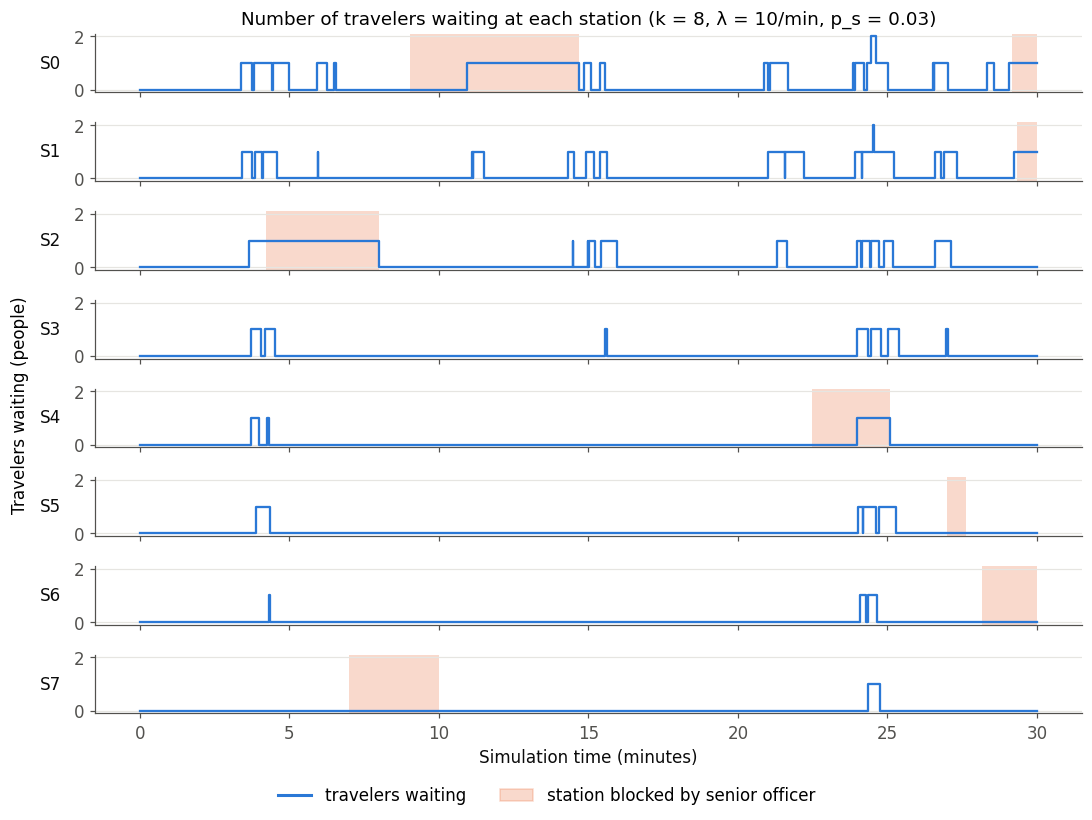

In [ ]:
state_demo = run_simulation(n_stations=N_STATIONS, run_until=30, seed=SEED, record_history=True)

def collapse_instantaneous(history):
    """Keep only the last recorded state at each timestamp. A traveler who joins an
    idle station and starts screening at the same instant never actually waits,
    so those zero-duration entries are dropped from the plot."""
    return [entry for entry, following in zip(history, history[1:] + [(np.inf,)]) if following[0] > entry[0]]


fig, axes = plt.subplots(N_STATIONS, 1, figsize=(10, 7.5), sharex=True, sharey=True)
for ax, queue in zip(axes, state_demo.queues):
    history = collapse_instantaneous(queue.history)
    times = np.array([h[0] for h in history])
    lengths = np.array([h[1] for h in history])
    states = [h[2] for h in history]
    ax.step(times, lengths, where='post', color=BLUE, linewidth=1.5)
    # Shade the intervals when the station is blocked by the senior officer
    for i in range(len(times) - 1):
        if states[i] == Queue.BLOCKED:
            ax.axvspan(times[i], times[i + 1], color=ORANGE, alpha=0.25, linewidth=0)
    ax.set_ylabel(f'S{queue.queue_id}', rotation=0, labelpad=15, va='center')
    ax.grid(axis='x')
axes[0].set_title(f'Number of travelers waiting at each station (k = {N_STATIONS}, λ = {ARRIVAL_RATE}/min, p_s = {SENIOR_PROB})')
axes[-1].set_xlabel('Simulation time (minutes)')
fig.text(0.01, 0.5, 'Travelers waiting (people)', rotation=90, va='center')
fig.legend(handles=[plt.Line2D([], [], color=BLUE, label='travelers waiting'),
                    Patch(color=ORANGE, alpha=0.25, label='station blocked by senior officer')],
           loc='lower center', ncol=2)
plt.tight_layout(rect=(0.02, 0.04, 1, 1))
plt.show()

**Figure 1.** State of one 30-minute run of the extended model with k = 8 stations. Each panel shows the number of travelers *waiting* (not counting the one being screened) at one station. Orange spans mark times when that station is blocked by a senior-officer check.

Shortest-queue routing keeps the eight lines within about one person of each other. Lines grow mainly while their station is blocked. Once the blocked traveler is cleared, the backlog clears and arrivals move to other stations in the meantime. This matches the intended behavior.

### 5.3 Exact hand-computed test cases

For these tests we feed in **deterministic** inter-arrival and service times, so the correct output can be worked out by hand and compared exactly.

In [ ]:
def check(condition, description):
    """Print PASS for a satisfied check. Otherwise raise an AssertionError with the description."""
    assert condition, f'FAILED: {description}'
    print(f'PASS  {description}')


# Test A: one station, arrivals every 0.2 min, service 0.5 min, no officer.
# Traveler n arrives at 0.2n and starts at 0.2 + 0.5(n − 1), so waits = 0, 0.3, 0.6, 0.9, ...
airport = run_simulation(n_stations=1, arrival_distribution=Deterministic(0.2),
                         service_distribution=Deterministic(0.5), senior_prob=0, run_until=3.0)
waits = np.array(airport.queues[0].waiting_times[:5])
check(np.allclose(waits, [0, 0.3, 0.6, 0.9, 1.2]), f'FIFO waiting times on one queue: {np.round(waits, 3)}')

# Test B: 3 stations, arrivals every 0.1 min, service 1.0 min.
# The first three travelers must take the three idle stations (S0, S1, S2) instead of piling into S0.
# Travelers 4-6 then join S0, S1, S2 in turn, because all lines are equal and ties go to the lowest id.
airport = run_simulation(n_stations=3, arrival_distribution=Deterministic(0.1),
                         service_distribution=Deterministic(1.0), senior_prob=0,
                         run_until=0.65, record_history=True)
check(airport.routing_log == [0, 1, 2, 0, 1, 2], f'shortest-queue routing order: {airport.routing_log}')

# Test C: one station, every traveler referred (p_s = 1), service 0.5, officer 1.0, arrivals every 1.0.
# Each traveler blocks the station for 1.5 min, so the backlog grows by 0.5 min per traveler.
airport = run_simulation(n_stations=1, arrival_distribution=Deterministic(1.0),
                         service_distribution=Deterministic(0.5), senior_prob=1.0,
                         senior_distribution=Deterministic(1.0), run_until=6.0)
waits = np.array(airport.queues[0].waiting_times[:4])
check(np.allclose(waits, [0, 0.5, 1.0, 1.5]), f'station blocked during senior screening: waits {np.round(waits, 3)}')

# Test D: two stations share ONE officer. Arrivals at 0.1 and 0.2, service 0.1, officer 1.0.
# S0's traveler sees the officer over [0.2, 1.2]. S1's traveler finishes regular screening
# at 0.3 but must wait for the officer, so it is screened over [1.2, 2.2].
airport = run_simulation(n_stations=2, arrival_distribution=Deterministic(0.1),
                         service_distribution=Deterministic(0.1), senior_prob=1.0,
                         senior_distribution=Deterministic(1.0), run_until=2.25, record_history=True)
first_two = [(sid, round(start, 6), round(end, 6)) for sid, start, end in airport.senior_officer.log[:2]]
check(first_two == [(0, 0.2, 1.2), (1, 1.2, 2.2)], f'one shared officer, one traveler at a time: {first_two}')

PASS  FIFO waiting times on one queue: [0.  0.3 0.6 0.9 1.2]
PASS  shortest-queue routing order: [0, 1, 2, 0, 1, 2]
PASS  station blocked during senior screening: waits [0.  0.5 1.  1.5]
PASS  one shared officer, one traveler at a time: [(0, np.float64(0.2), np.float64(1.2)), (1, np.float64(1.2), np.float64(2.2))]


### 5.4 Statistical checks against theory

- **Conservation.** Every traveler who arrived has either left, is waiting, or is at a station.
- **Little's law.** For each queue, $L_q = \lambda_{\text{queue}} W_q$. Summed over queues, the total number waiting equals λ × (mean wait). This holds for *any* stable queueing system, so it checks that our two metrics are measured consistently.
- **M/G/1 theory.** With k = 1 the model is exactly an M/G/1 queue, so the Pollaczek–Khinchine formula must match the simulation. We check this across utilizations ρ and for three service distributions.
- **Overload.** When ρ > 1, the total backlog must grow linearly at rate λ − k/E[S].
- **Reproducibility.** The same seed gives identical output, and a different seed gives different output.

In [ ]:
# Conservation of travelers and Little's law, from one long run of the extended model
airport = run_simulation(n_stations=N_STATIONS, warmup=100, run_until=2100, seed=SEED)
in_line = sum(q.length for q in airport.queues)
at_station = sum(q.is_station_busy for q in airport.queues)
departed = sum(q.n_departed for q in airport.queues)
check(airport.n_arrivals == departed + in_line + at_station,
      f'conservation: {airport.n_arrivals} arrived = {departed} departed + {in_line} waiting + {at_station} at stations')

res = airport.results()
total_waiting = res['mean_queue_length'] * N_STATIONS          # time-average number waiting, all queues
littles_prediction = ARRIVAL_RATE * res['mean_waiting_time']    # λ × W_q
check(abs(total_waiting / littles_prediction - 1) < 0.03,
      f"Little's law: L_q = {total_waiting:.3f} vs λ·W_q = {littles_prediction:.3f} "
      f'({100 * abs(total_waiting / littles_prediction - 1):.1f}% apart)')

# Reproducibility
check(run_simulation(seed=5, run_until=50).results() == run_simulation(seed=5, run_until=50).results(),
      'same seed → identical results')
check(run_simulation(seed=5, run_until=50).results() != run_simulation(seed=6, run_until=50).results(),
      'different seed → different results')

PASS  conservation: 21044 arrived = 21007 departed + 29 waiting + 8 at stations
PASS  Little's law: L_q = 10.645 vs λ·W_q = 10.623 (0.2% apart)
PASS  same seed → identical results
PASS  different seed → different results


In [ ]:
# Single queue (k = 1) against Pollaczek–Khinchine, for three service distributions at ρ ≈ 0.8
MG1_RUNS, MG1_WARMUP, MG1_LENGTH = 30, 200, 3000
single_queue_cases = {
    'M/D/1  (deterministic 0.5 min)': Deterministic(0.5),
    'M/M/1  (exponential, mean 0.5 min)': sts.expon(scale=0.5),
    'M/G/1  (TN(µ1, σ1), the regular screening)': regular_screening,
}
print(f'{"model":<45}{"theory L_q":>12}{"simulated L_q (95% CI)":>28}   verdict')
for label, distribution in single_queue_cases.items():
    rate = 0.8 / distribution.mean()                      # choose λ so that ρ = 0.8
    theory = mg1_mean_queue_length(rate, distribution)
    trial = run_trials(MG1_RUNS, base_seed=1000, n_stations=1, arrival_rate=rate,
                       service_distribution=distribution, senior_prob=0,
                       warmup=MG1_WARMUP, run_until=MG1_WARMUP + MG1_LENGTH)
    mean, half = mean_ci(trial['mean_queue_length'])
    verdict = 'theory inside CI' if abs(mean - theory) <= half else 'outside CI'
    print(f'{label:<45}{theory:>12.3f}{mean:>16.3f} ± {half:.3f}      {verdict}')

model                                          theory L_q      simulated L_q (95% CI)   verdict
M/D/1  (deterministic 0.5 min)                      1.600           1.579 ± 0.071      theory inside CI
M/M/1  (exponential, mean 0.5 min)                  3.200           3.152 ± 0.151      theory inside CI
M/G/1  (TN(µ1, σ1), the regular screening)          1.775           1.757 ± 0.080      theory inside CI


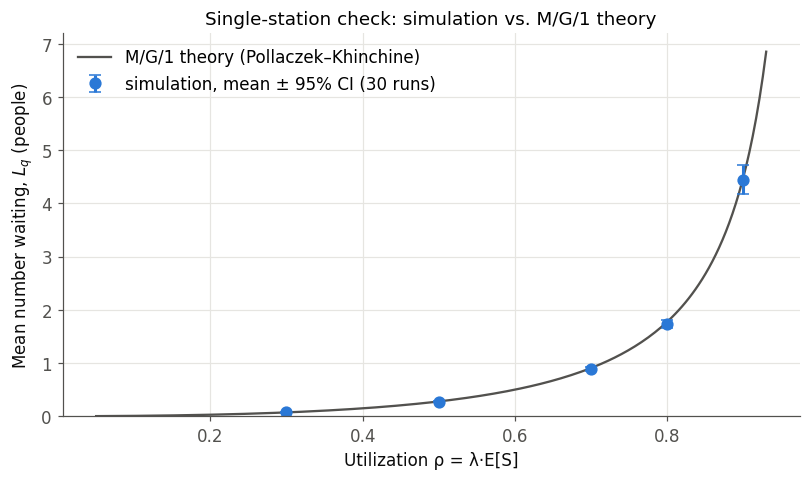

ρ = 0.3: theory  0.071   simulation  0.071 ± 0.003
ρ = 0.5: theory  0.277   simulation  0.274 ± 0.009
ρ = 0.7: theory  0.906   simulation  0.883 ± 0.033
ρ = 0.8: theory  1.775   simulation  1.732 ± 0.081
ρ = 0.9: theory  4.493   simulation  4.450 ± 0.280


In [ ]:
# M/G/1 sweep across utilization, with the regular screening distribution
rhos = np.array([0.3, 0.5, 0.7, 0.8, 0.9])
theory_curve_rho = np.linspace(0.05, 0.93, 200)
sim_means, sim_halves = [], []
for rho in rhos:
    trial = run_trials(MG1_RUNS, base_seed=2000, n_stations=1, arrival_rate=rho / tau,
                       senior_prob=0, warmup=MG1_WARMUP, run_until=MG1_WARMUP + MG1_LENGTH)
    mean, half = mean_ci(trial['mean_queue_length'])
    sim_means.append(mean)
    sim_halves.append(half)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.plot(theory_curve_rho, [mg1_mean_queue_length(r / tau, regular_screening) for r in theory_curve_rho],
        color=MUTED, linewidth=1.5, label='M/G/1 theory (Pollaczek–Khinchine)')
ax.errorbar(rhos, sim_means, yerr=sim_halves, fmt='o', color=BLUE, markersize=7, capsize=4,
            label=f'simulation, mean ± 95% CI ({MG1_RUNS} runs)')
ax.set_xlabel('Utilization ρ = λ·E[S]')
ax.set_ylabel('Mean number waiting, $L_q$ (people)')
ax.set_title('Single-station check: simulation vs. M/G/1 theory')
ax.set_ylim(bottom=0)
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

for rho, mean, half in zip(rhos, sim_means, sim_halves):
    theory = mg1_mean_queue_length(rho / tau, regular_screening)
    print(f'ρ = {rho:.1f}: theory {theory:6.3f}   simulation {mean:6.3f} ± {half:.3f}')

**Figure 2.** Mean number of travelers waiting in a single-station system (k = 1, no senior officer), with service times from the regular screening distribution TN(µ1 = 0.5 min, σ1 = 1/6 min). The gray curve is the Pollaczek–Khinchine formula, which uses the true (truncated) mean and variance. Dots are simulation means over 30 independent runs, each 3,000 minutes long after a 200-minute warm-up, with 95% confidence intervals of the mean.

Theory and simulation agree at every utilization. This confirms the arrival process, the service draws, the FIFO discipline and the time-averaged queue-length measurement. The intervals widen as ρ → 1, because the queue has longer memory and takes longer to average out near saturation.

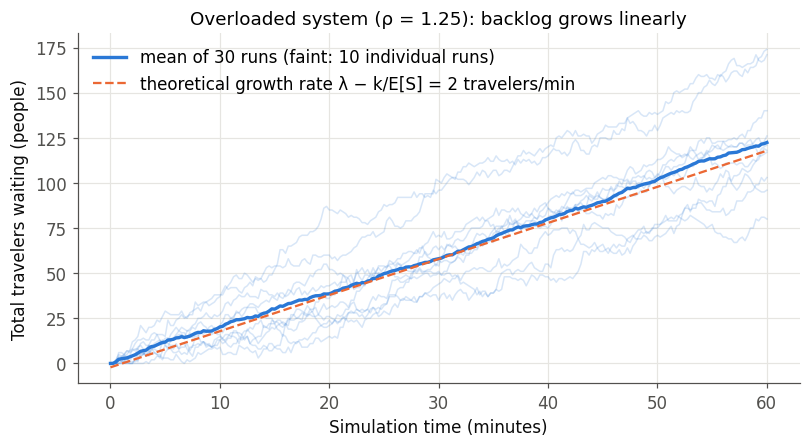

PASS  overload growth rate 2.07/min vs expected 2.00/min


In [ ]:
# Overload (ρ > 1): 4 stations with uniform(0, 1) service have capacity 4 / 0.5 = 8 travelers/min,
# but λ = 10/min. The total backlog should grow at about λ − k/E[S] = 2 travelers/min.
OVERLOAD_STATIONS, OVERLOAD_MINUTES, OVERLOAD_RUNS = 4, 60, 30
uniform_service = sts.uniform(loc=0, scale=1)
expected_slope = ARRIVAL_RATE - OVERLOAD_STATIONS / uniform_service.mean()
grid = np.linspace(0, OVERLOAD_MINUTES, 241)


def total_waiting_on_grid(airport, grid):
    """Total number waiting across all queues at each grid time, read from the recorded histories."""
    total = np.zeros_like(grid)
    for queue in airport.queues:
        times = np.array([h[0] for h in queue.history])
        lengths = np.array([h[1] for h in queue.history])
        total += lengths[np.searchsorted(times, grid, side='right') - 1]
    return total


backlogs = np.array([
    total_waiting_on_grid(run_simulation(n_stations=OVERLOAD_STATIONS, service_distribution=uniform_service,
                                         senior_prob=0, run_until=OVERLOAD_MINUTES, seed=3000 + i,
                                         record_history=True), grid)
    for i in range(OVERLOAD_RUNS)])
mean_backlog = backlogs.mean(axis=0)
after_transient = grid >= 10
fitted_slope, intercept = np.polyfit(grid[after_transient], mean_backlog[after_transient], 1)

fig, ax = plt.subplots(figsize=(7.5, 4.2))
for run in backlogs[:10]:
    ax.plot(grid, run, color=BLUE, alpha=0.18, linewidth=1)
ax.plot(grid, mean_backlog, color=BLUE, linewidth=2.2, label=f'mean of {OVERLOAD_RUNS} runs (faint: 10 individual runs)')
ax.plot(grid, intercept + expected_slope * grid, color=ORANGE, linestyle='--', linewidth=1.5,
        label=f'theoretical growth rate λ − k/E[S] = {expected_slope:.0f} travelers/min')
ax.set_xlabel('Simulation time (minutes)')
ax.set_ylabel('Total travelers waiting (people)')
ax.set_title('Overloaded system (ρ = 1.25): backlog grows linearly')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()
check(abs(fitted_slope / expected_slope - 1) < 0.10,
      f'overload growth rate {fitted_slope:.2f}/min vs expected {expected_slope:.2f}/min')

**Figure 3.** Total number waiting over time when the system is deliberately overloaded: λ = 10 travelers/min, k = 4 stations, uniform(0, 1) service with mean 0.5 min, so capacity is 8 travelers/min and ρ = 1.25. The fitted slope after the first 10 minutes matches the predicted net inflow of 2 travelers/min. The simulation correctly produces no steady state when ρ ≥ 1.

### 5.5 Why "shortest queue" must count the traveler at the station

A natural but wrong implementation compares only the number of people *waiting*. Then a line with an idle station and a line with a busy station both count as length 0, and `min()` sends the traveler to the first one, which may be busy. The traveler waits behind someone while another station sits empty. The ablation below swaps in that rule, using the `queue_class` option, on test set 1.

In [ ]:
class QueueComparedByWaitingOnly(Queue):
    """A Queue that ignores whether its station is busy when choosing the shortest line. Used only for this comparison."""
    def __lt__(self, other):
        return self.length < other.length


set1_kwargs = dict(n_stations=6, service_distribution=sts.uniform(loc=0, scale=1),
                   senior_prob=0, warmup=100, run_until=100 + MEASURE_MINUTES)
for label, queue_class in [('number in system (waiting + at station)', Queue),
                           ('number waiting only', QueueComparedByWaitingOnly)]:
    trial = run_trials(50, base_seed=4000, queue_class=queue_class, **set1_kwargs)
    mean, half = mean_ci(trial['mean_queue_length'])
    print(f'Routing by {label:<42}: mean queue length {mean:.3f} ± {half:.3f}   (target 0.463 ± 0.025)')

Routing by number in system (waiting + at station)   : mean queue length 0.455 ± 0.024   (target 0.463 ± 0.025)
Routing by number waiting only                       : mean queue length 0.802 ± 0.023   (target 0.463 ± 0.025)


Comparing only waiting counts nearly doubles the mean queue length and misses the target by a wide margin. The benchmark values assume travelers walk to an idle station when one is free. We therefore define "shortest queue" as **fewest people in the system**. Section 6 uses this definition throughout.

## 6. Part 1 test cases

| | Set 1 | Set 2 |
|---|---|---|
| Arrivals | Exponential, λ = 10/min | Exponential, λ = 10/min |
| Service | Uniform(0, 1) min | TN(1, 1) truncated at 0, true mean 1.288 min |
| Stations k | 6 | 14 |
| Utilization ρ = λE[S]/k | 0.833 | 0.920 |
| Target mean queue length | 0.463 ± 0.025 | 0.566 ± 0.025 |
| Suggested warm-up | 100 min | 200 min |

The basic model has no senior officer, so these runs use p_s = 0. The metric is the **time-averaged number of travelers waiting per queue**, excluding the traveler at the station. If the traveler being served were counted, set 1 would already have ρ ≈ 0.83 people per queue from service alone, well above the target of 0.463. So the target must count waiting travelers only.

In [ ]:
TEST_CASES = {
    'Set 1': dict(n_stations=6, service_distribution=sts.uniform(loc=0, scale=1),
                  warmup=100, target=0.463),
    'Set 2': dict(n_stations=14, service_distribution=sts.truncnorm(-1, np.inf, loc=1, scale=1),
                  warmup=200, target=0.566),
}
for name, case in TEST_CASES.items():
    service = case['service_distribution']
    rho = ARRIVAL_RATE * service.mean() / case['n_stations']
    print(f"{name}: k = {case['n_stations']}, E[S] = {service.mean():.3f} min, "
          f"Var[S] = {service.var():.3f} min², ρ = {rho:.3f}")

Set 1: k = 6, E[S] = 0.500 min, Var[S] = 0.083 min², ρ = 0.833
Set 2: k = 14, E[S] = 1.288 min, Var[S] = 0.630 min², ρ = 0.920


### 6.1 Stationarity: how long until the start-up transient is gone?

Every run starts with an **empty** airport, so early measurements are biased low. To see when the system reaches its stationary state, we run 200 independent replications of each test case for three times the suggested warm-up and record the full history. We then plot two things:

1. **Ensemble mean at time t.** At each moment we average the number waiting across all stations and all 200 runs. This is exactly the estimator "run for t minutes and look at the queue", as in the pre-class work. It should rise from 0 and then flatten.
2. **Running time-average from t = 0.** This is what we would get by averaging over the whole run *without* discarding a warm-up. It stays biased low for much longer, which is why we discard the warm-up.

In [20]:
N_STATIONARITY_RUNS = 200


def time_average_curves(airport, grid):
    """
    Return, at each grid time t:
      snapshot   : number waiting per queue at time t
      cumulative : time-average number waiting per queue over [0, t], computed exactly
                   because the area under a step function is piecewise linear
    """
    snapshots, areas = [], []
    for queue in airport.queues:
        times = np.array([h[0] for h in queue.history])
        lengths = np.array([h[1] for h in queue.history])
        snapshots.append(lengths[np.searchsorted(times, grid, side='right') - 1])
        cumulative_area = np.concatenate([[0.0], np.cumsum(lengths[:-1] * np.diff(times))])
        areas.append(np.interp(grid, times, cumulative_area))
    snapshot = np.mean(snapshots, axis=0)
    with np.errstate(invalid='ignore', divide='ignore'):
        cumulative = np.mean(areas, axis=0) / grid
    return snapshot, cumulative


stationarity = {}
for index, (name, case) in enumerate(TEST_CASES.items()):
    horizon = 3 * case['warmup']
    grid = np.linspace(0, horizon, int(horizon) + 1)   # one point per minute
    snapshots, cumulatives = [], []
    for i in range(N_STATIONARITY_RUNS):
        airport = run_simulation(n_stations=case['n_stations'], service_distribution=case['service_distribution'],
                                 senior_prob=0, run_until=horizon, seed=10_000 * (index + 1) + i,
                                 record_history=True)
        snapshot, cumulative = time_average_curves(airport, grid)
        snapshots.append(snapshot)
        cumulatives.append(cumulative)
    stationarity[name] = dict(grid=grid, snapshots=np.array(snapshots), cumulatives=np.array(cumulatives))

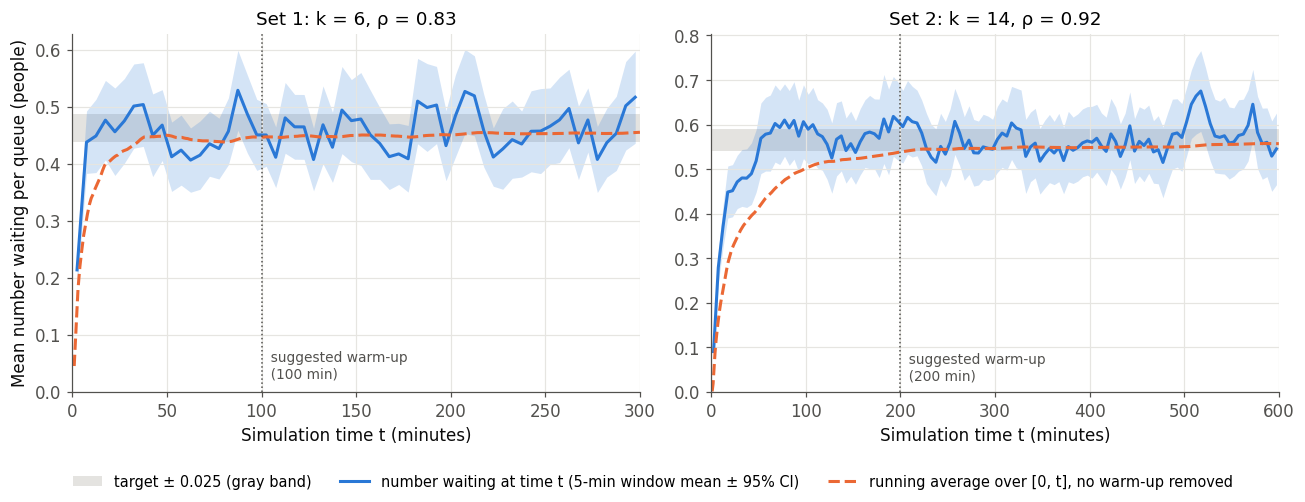

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, (name, case) in zip(axes, TEST_CASES.items()):
    data = stationarity[name]
    grid = data['grid']
    # Smooth the ensemble snapshot into 5-minute windows to make the plateau easier to see
    window = 5
    n_windows = (len(grid) - 1) // window
    window_centres = grid[:-1].reshape(n_windows, window).mean(axis=1) + 0.5
    window_values = data['snapshots'][:, :-1].reshape(len(data['snapshots']), n_windows, window).mean(axis=2)
    window_mean = window_values.mean(axis=0)
    window_half = sts.t.ppf(0.975, len(window_values) - 1) * window_values.std(axis=0, ddof=1) / np.sqrt(len(window_values))

    ax.axhspan(case['target'] - TARGET_TOLERANCE, case['target'] + TARGET_TOLERANCE, color=BAND, alpha=0.7,
               linewidth=0, label=f"target {case['target']} ± {TARGET_TOLERANCE}")
    ax.fill_between(window_centres, window_mean - window_half, window_mean + window_half, color=BLUE, alpha=0.2, linewidth=0)
    ax.plot(window_centres, window_mean, color=BLUE, label='number waiting at time t (5-min window mean ± 95% CI)')
    ax.plot(grid[1:], data['cumulatives'].mean(axis=0)[1:], color=ORANGE, linestyle='--',
            label='running average over [0, t], no warm-up removed')
    ax.axvline(case['warmup'], color=MUTED, linewidth=1, linestyle=':')
    ax.text(case['warmup'], 0.02, f"  suggested warm-up\n  ({case['warmup']} min)", color=MUTED, fontsize=9, va='bottom')
    ax.set_title(f"{name}: k = {case['n_stations']}, ρ = {ARRIVAL_RATE * case['service_distribution'].mean() / case['n_stations']:.2f}")
    ax.set_xlabel('Simulation time t (minutes)')
    ax.set_ylim(0, None)
    ax.set_xlim(0, grid[-1])
axes[0].set_ylabel('Mean number waiting per queue (people)')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, ['target ± 0.025 (gray band)', labels[1], labels[2]], loc='lower center', ncol=3, fontsize=9.5)
plt.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

**Figure 4.** Transient behavior of the two test cases, averaged over 200 independent runs that each start from an empty airport. The blue line is the mean number waiting per queue at time t, averaged in 5-minute windows, with its 95% confidence band. The orange dashed line is the running average from t = 0, which keeps the start-up transient. The gray band is the provided target, and the dotted line marks the suggested warm-up.

In [22]:
print('Mean number waiting per queue in consecutive windows (ensemble of 200 runs, 95% CI):')
for name, case in TEST_CASES.items():
    data = stationarity[name]
    grid, snapshots = data['grid'], data['snapshots']
    width = case['warmup'] / 2
    print(f'\n{name}:')
    for start in np.arange(0, grid[-1], width):
        in_window = (grid >= start) & (grid < start + width)
        mean, half = mean_ci(snapshots[:, in_window].mean(axis=1))
        print(f'   [{start:5.0f}, {start + width:5.0f}) min : {mean:.3f} ± {half:.3f}')

Mean number waiting per queue in consecutive windows (ensemble of 200 runs, 95% CI):

Set 1:
   [    0,    50) min : 0.443 ± 0.030
   [   50,   100) min : 0.444 ± 0.027
   [  100,   150) min : 0.455 ± 0.026
   [  150,   200) min : 0.455 ± 0.032
   [  200,   250) min : 0.462 ± 0.029
   [  250,   300) min : 0.467 ± 0.030

Set 2:
   [    0,   100) min : 0.500 ± 0.038
   [  100,   200) min : 0.575 ± 0.047
   [  200,   300) min : 0.562 ± 0.044
   [  300,   400) min : 0.555 ± 0.040
   [  400,   500) min : 0.557 ± 0.043
   [  500,   600) min : 0.592 ± 0.047


**Empirical evidence of stationarity.**

- **Set 1 (ρ = 0.83).** The ensemble mean climbs from 0 and levels off within about 10–15 minutes. From then on, successive 50-minute windows overlap (0.44–0.47) and sit in the target band. Overlapping windows provide empirical evidence of stationarity. The suggested 100-minute warm-up is conservative by a wide margin.
- **Set 2 (ρ = 0.92).** Closer to saturation, the system relaxes more slowly: the ensemble mean levels off after about 50–60 minutes. The first 100-minute window (0.500) is clearly below all later ones (0.555–0.592), and the later windows overlap. A 200-minute warm-up is past that visible transient in these runs. The overlap provides empirical evidence of stationarity. It does not prove it, and the bias lasts longer as the load increases.

The running average from t = 0 (orange) shows why discarding the warm-up matters. For set 2 it is still about 0.54 at t = 200 min, below the plateau of about 0.56, because the empty start drags it down. The heavier the load, the longer this bias persists. We therefore discard the warm-up and measure only afterwards. We calibrated these run lengths on the test cases, but they do **not** automatically carry over to the extended model (Section 7.4).

### 6.2 Final estimates against the targets

The protocol for each test case is:

1. Run **200 independent replications**.
2. Discard the suggested warm-up (100 or 200 minutes).
3. Measure the time-averaged number waiting per queue over the next 400 minutes. This gives one value per run.
4. Report the mean and its 95% confidence interval.

For comparison we also report the pre-class estimator, a snapshot of the number waiting at the final instant. Once the system is stationary, both estimate the same quantity (ergodicity). The time average is more precise because it uses the whole window rather than a single moment.

In [23]:
test_results = {}
print(f'{"":<7}{"target":>16}{"time-average (95% CI)":>26}{"end snapshot (95% CI)":>26}   verdict')
for index, (name, case) in enumerate(TEST_CASES.items()):
    trial = run_trials(N_TEST_RUNS, base_seed=50_000 * (index + 1), n_stations=case['n_stations'],
                       service_distribution=case['service_distribution'], senior_prob=0,
                       warmup=case['warmup'], run_until=case['warmup'] + MEASURE_MINUTES)
    time_avg = mean_ci(trial['mean_queue_length'])
    snapshot = mean_ci(trial['end_queue_length'])
    test_results[name] = dict(time_average=time_avg, snapshot=snapshot)
    low, high = case['target'] - TARGET_TOLERANCE, case['target'] + TARGET_TOLERANCE
    # Pass if our confidence interval overlaps the target interval
    passed = (time_avg[0] - time_avg[1] <= high) and (time_avg[0] + time_avg[1] >= low)
    print(f"{name:<7}{case['target']:>10.3f} ± {TARGET_TOLERANCE:.3f}"
          f"{time_avg[0]:>16.3f} ± {time_avg[1]:.3f}{snapshot[0]:>16.3f} ± {snapshot[1]:.3f}   "
          f"{'PASS' if passed else 'FAIL'}")
    assert passed, f'{name} does not match its target.'

                 target     time-average (95% CI)     end snapshot (95% CI)   verdict
Set 1       0.463 ± 0.025           0.457 ± 0.012           0.485 ± 0.091   PASS
Set 2       0.566 ± 0.025           0.555 ± 0.021           0.589 ± 0.081   PASS


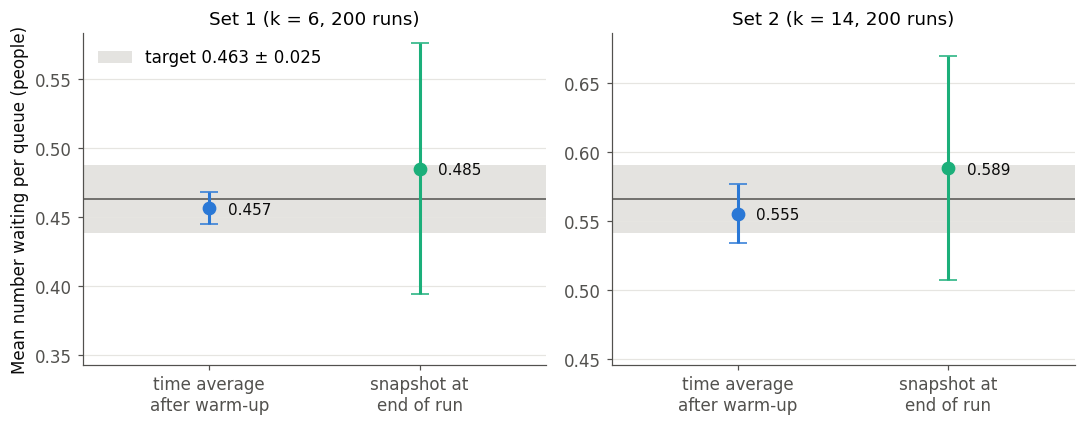

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, case) in zip(axes, TEST_CASES.items()):
    ax.axhspan(case['target'] - TARGET_TOLERANCE, case['target'] + TARGET_TOLERANCE, color=BAND, alpha=0.7,
               linewidth=0, label=f"target {case['target']} ± {TARGET_TOLERANCE}")
    ax.axhline(case['target'], color=MUTED, linewidth=1)
    for x, (key, label, color) in enumerate([('time_average', 'time average\nafter warm-up', BLUE),
                                             ('snapshot', 'snapshot at\nend of run', AQUA)]):
        mean, half = test_results[name][key]
        ax.errorbar(x, mean, yerr=half, fmt='o', color=color, markersize=8, capsize=6, linewidth=2)
        ax.annotate(f'{mean:.3f}', (x, mean), textcoords='offset points', xytext=(12, -4), color=INK, fontsize=10)
    ax.set_xticks([0, 1], ['time average\nafter warm-up', 'snapshot at\nend of run'])
    ax.set_xlim(-0.6, 1.6)
    centre = case['target']
    ax.set_ylim(centre - 0.12, centre + 0.12)
    ax.set_title(f"{name} (k = {case['n_stations']}, {N_TEST_RUNS} runs)")
    ax.grid(axis='x')
axes[0].set_ylabel('Mean number waiting per queue (people)')
axes[0].legend(loc='upper left')
plt.tight_layout()
plt.show()

**Figure 5.** Simulated mean queue length per queue for both test cases, with 95% confidence intervals of the mean over 200 independent runs. Each run discards a warm-up of 100 min (set 1) or 200 min (set 2) and then measures for 400 min. The gray band is the provided target ± 0.025. The vertical axis is zoomed around each target and does not start at zero.

Both estimators fall inside the target band for both test cases, so the basic model reproduces the expected behavior. The snapshot estimator has a much wider interval because it uses one moment per run rather than 400 minutes.

## 7. Extended model: the senior security officer

### 7.1 What changed in the code

The officer was added with four small, local changes. The basic model is the special case p_s = 0.

1. **New class `SeniorOfficer`.** It holds the officer's state (`is_busy`, and `waiting_stations`, a FIFO line of blocked stations) and three event methods: `request_screening`, `start_screening` and `finish_screening`. Because there is one officer instance, at most one traveler is screened at a time, airport-wide.
2. **`Queue.finish_service` now branches.** With probability p_s, drawn by `Airport.needs_additional_screening`, the station is marked `is_blocked` and stays occupied, and the officer is requested. Otherwise the traveler leaves through `_release_station`, as before.
3. **New `Queue.finish_additional_screening`.** The officer calls it when finished. It unblocks the station and calls `_release_station`, which starts the next traveler in that line. While blocked, `is_station_busy` stays True, so no one else in that line can start screening. Other lines are not affected.
4. **`Airport` owns the officer and the referral stream.** p_s, µ2 and σ2 are set once in the parameters cell. The referral decisions and senior screening times use their **own** random streams, so switching the officer off leaves the arrival and service draws unchanged.

### 7.2 Reduction checks

The assignment asks us to confirm that the extension reduces to the basic model. Because of the common random numbers, we can check this **exactly**, traveler by traveler, rather than only statistically.

- **p_s = 0.** Nobody is referred, so the output must be identical to the basic model.
- **µ2 = σ2 = 0 (with p_s = 0.03).** Referrals happen, but take zero time. The officer's code path runs, yet every traveler's timeline must be identical to the basic model.
- **µ2 = σ2 = 0 with p_s = 1.** This is the most demanding version: *every* traveler goes through the officer, in zero time.

In [ ]:
def all_waiting_times(airport):
    """Every traveler's waiting time, grouped by station, for exact comparison between runs."""
    return [np.array(q.waiting_times) for q in airport.queues]


comparison_options = dict(n_stations=N_STATIONS, run_until=200, seed=SEED)
basic = all_waiting_times(run_simulation(senior_prob=0, **comparison_options))
variants = {
    'p_s = 0 (default µ2, σ2)': run_simulation(senior_prob=0, **comparison_options),
    'µ2 = σ2 = 0, p_s = 0.03': run_simulation(senior_prob=SENIOR_PROB, senior_distribution=truncated_normal(0, 0),
                                              **comparison_options),
    'µ2 = σ2 = 0, p_s = 1': run_simulation(senior_prob=1.0, senior_distribution=truncated_normal(0, 0),
                                           **comparison_options),
}
n_basic = sum(len(w) for w in basic)
for label, airport in variants.items():
    identical = all(np.array_equal(a, b) for a, b in zip(basic, all_waiting_times(airport)))
    check(identical, f'{label:<26} reproduces all {n_basic} waiting times of the basic model exactly '
                     f'({airport.senior_officer.n_screened} zero-time referrals)')

PASS  p_s = 0 (default µ2, σ2)   reproduces all 2085 waiting times of the basic model exactly (0 zero-time referrals)
PASS  µ2 = σ2 = 0, p_s = 0.03    reproduces all 2085 waiting times of the basic model exactly (60 zero-time referrals)
PASS  µ2 = σ2 = 0, p_s = 1       reproduces all 2085 waiting times of the basic model exactly (2078 zero-time referrals)


### 7.3 Does the officer behave as specified?

The officer's own workload gives two direct checks:

- The fraction of travelers referred should be p_s = 0.03.
- In a stable system every referred traveler is eventually cleared, so the officer's utilization must equal λ · p_s · E[S2] = 10 × 0.03 × 2.575 ≈ 0.773. This is the utilization of a single server fed at rate λp_s.

We run these checks at k = 10, above the approximate capacity threshold. The officer's line is heavily loaded, so the queues move slowly. We therefore use a 300-minute warm-up and a 1,500-minute measurement window.

In [ ]:
OFFICER_CHECK_STATIONS, OFFICER_RUNS, OFFICER_WARMUP, OFFICER_WINDOW = 10, 60, 300, 1500
officer_trials = run_trials(OFFICER_RUNS, base_seed=70_000, n_stations=OFFICER_CHECK_STATIONS,
                            senior_prob=SENIOR_PROB, warmup=OFFICER_WARMUP,
                            run_until=OFFICER_WARMUP + OFFICER_WINDOW)
referral = mean_ci(officer_trials['referral_fraction'])
utilization = mean_ci(officer_trials['officer_utilization'])
print(f'k = {OFFICER_CHECK_STATIONS}, {OFFICER_RUNS} runs:')
print(f'  referral fraction   {referral[0]:.4f} ± {referral[1]:.4f}   (expected p_s = {SENIOR_PROB})')
print(f'  officer utilization {utilization[0]:.3f} ± {utilization[1]:.3f}   (expected λ·p_s·E[S2] = {officer_load:.3f})')
check(abs(referral[0] - SENIOR_PROB) <= 2 * referral[1], 'referral fraction consistent with p_s')
check(abs(utilization[0] - officer_load) <= 2 * utilization[1], 'officer utilization consistent with λ·p_s·E[S2]')

k = 10, 60 runs:
  referral fraction   0.0301 ± 0.0003   (expected p_s = 0.03)
  officer utilization 0.778 ± 0.007   (expected λ·p_s·E[S2] = 0.773)
PASS  referral fraction consistent with p_s
PASS  officer utilization consistent with λ·p_s·E[S2]


### 7.4 A finding for Part 2: the officer changes how many stations are needed

A referred traveler occupies their station for longer than their regular screening. They also stay there while *waiting* for the officer, and then during the additional screening. So the mean time each traveler occupies a station is roughly

$$h \approx E[S_1] + p_s\left(W_{\text{officer}} + E[S_2]\right),$$

where $W_{\text{officer}}$ is the wait for the officer. We estimate $W_{\text{officer}}$ by treating the officer as an M/G/1 queue with arrival rate λp_s. This is an approximation, because referrals are a thinned stream of station departures rather than an exact Poisson process. Stability then needs λh/k < 1, i.e. k > λh.

In [27]:
officer_rate = ARRIVAL_RATE * SENIOR_PROB
officer_wait = mg1_mean_queue_length(officer_rate, senior_screening) / officer_rate   # Little's law: W = L_q / λ
holding_time = regular_screening.mean() + SENIOR_PROB * (officer_wait + senior_screening.mean())
print(f'Estimated wait for the officer (M/G/1, λ = {officer_rate:.2f}/min): {officer_wait:.2f} min')
print(f'Mean station occupancy per traveler h ≈ {regular_screening.mean():.3f} + {SENIOR_PROB} × ({officer_wait:.2f} + {senior_screening.mean():.3f}) = {holding_time:.3f} min')
print(f'Approximate threshold k > λ·h = {ARRIVAL_RATE * holding_time:.2f}  →  k ≥ {int(np.floor(ARRIVAL_RATE * holding_time)) + 1}'
      f'   (compared with k ≥ 6 for the basic model; this does not establish stability of k = 7)')

Estimated wait for the officer (M/G/1, λ = 0.30/min): 6.03 min
Mean station occupancy per traveler h ≈ 0.501 + 0.03 × (6.03 + 2.575) = 0.759 min
Approximate threshold k > λ·h = 7.59  →  k ≥ 8   (compared with k ≥ 6 for the basic model; this does not establish stability of k = 7)


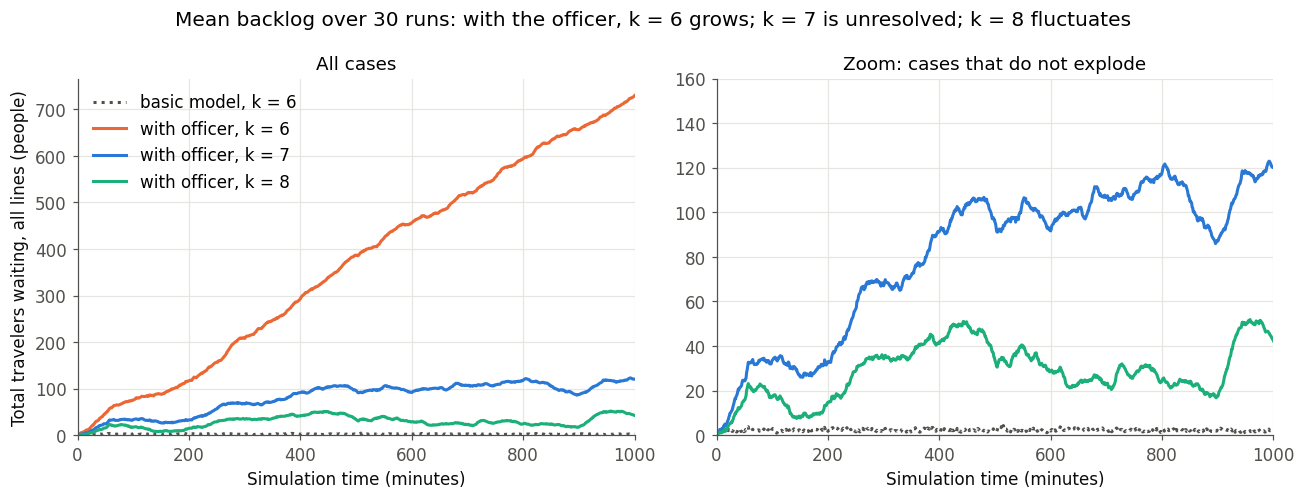

basic model, k = 6     mean backlog after 1000 min:     2.7 people
with officer, k = 6    mean backlog after 1000 min:   729.5 people
with officer, k = 7    mean backlog after 1000 min:   120.4 people
with officer, k = 8    mean backlog after 1000 min:    42.3 people


In [ ]:
STABILITY_RUNS, STABILITY_MINUTES = 30, 1000
stability_grid = np.linspace(0, STABILITY_MINUTES, STABILITY_MINUTES + 1)
stability_cases = [('basic model, k = 6', 6, 0.0, MUTED, ':'),
                   ('with officer, k = 6', 6, SENIOR_PROB, ORANGE, '-'),
                   ('with officer, k = 7', 7, SENIOR_PROB, BLUE, '-'),
                   ('with officer, k = 8', 8, SENIOR_PROB, AQUA, '-')]
backlogs_by_case = {}
for label, k, p_s, color, style in stability_cases:
    backlogs_by_case[label] = np.mean(
        [total_waiting_on_grid(run_simulation(n_stations=k, senior_prob=p_s, run_until=STABILITY_MINUTES,
                                              seed=80_000 + i, record_history=True), stability_grid)
         for i in range(STABILITY_RUNS)], axis=0)
final_backlog = {label: backlog[-1] for label, backlog in backlogs_by_case.items()}

fig, (ax_full, ax_zoom) = plt.subplots(1, 2, figsize=(12, 4.6))
for label, k, p_s, color, style in stability_cases:
    backlog = backlogs_by_case[label]
    ax_full.plot(stability_grid, backlog, color=color, linestyle=style, label=label)
    if k > 6 or p_s == 0:                       # the right panel zooms in on the non-exploding cases
        ax_zoom.plot(stability_grid, backlog, color=color, linestyle=style, label=label)
ax_full.set_title('All cases')
ax_zoom.set_title('Zoom: cases that do not explode')
ax_zoom.set_ylim(0, 160)
for ax in (ax_full, ax_zoom):
    ax.set_xlim(0, STABILITY_MINUTES)
    ax.set_xlabel('Simulation time (minutes)')
ax_full.set_ylim(bottom=0)
ax_full.set_ylabel('Total travelers waiting, all lines (people)')
ax_full.legend(loc='upper left')
fig.suptitle(f'Mean backlog over {STABILITY_RUNS} runs: with the officer, k = 6 grows; k = 7 is unresolved; k = 8 fluctuates')
plt.tight_layout()
plt.show()
for label, value in final_backlog.items():
    print(f'{label:<22} mean backlog after {STABILITY_MINUTES} min: {value:7.1f} people')

**Figure 6.** Mean total number of travelers waiting across all lines over 1,000 minutes (the right panel zooms in on the vertical axis), averaged over 30 independent runs from an empty airport (λ = 10/min; officer parameters p_s = 0.03, µ2 = σ2 = 2 min).

- Without the officer, 6 stations level off almost immediately (dotted gray).
- With the officer, 6 stations grow in this window: the backlog increases roughly linearly and shows no sign of leveling off.
- At 7 stations the mean path does not fall to a small queue, and it also does not show clear unbounded growth over these 1,000 minutes. Section 8.5 estimates the slope from minute 300 to minute 1,000 as about zero. That slope neither establishes that k = 7 is stable nor that it is unstable.
- At 8 stations the mean fluctuates, roughly 20–50 people in total, with long, slow swings. That is still far more than the basic model's handful of people. Fluctuation inside this window is not a proof that k = 8 is stable.

The paths are consistent with the approximate station-occupancy threshold k > 7.6. They do not identify a proven minimum stable station count.

**Implications for Part 2.**

1. The approximate theoretical threshold is about 7.6 stations, against 6 for the basic model. The stability of k = 7 in the complete coupled system has not been established, so this section does not treat k = 8 as a proven minimum.
2. The officer is busy about 77% of the time no matter how many stations there are, and adding stations cannot relieve that queue. Its delays are passed on to whole lines.
3. Because the officer's line is heavily loaded, the extended model moves much more slowly than the test cases do. The 100–200 minute warm-ups calibrated in Section 6 are **not** long enough here. Section 8.1 looks for empirical evidence on whether the 300-minute warm-up from Section 7.3 is long enough at k = 8 and k = 9, which sit closer to the capacity boundary than the k = 10 officer check, and then measures a full simulated day.

Section 8 starts from the approximate threshold. It looks for empirical evidence of stationarity at k = 8 and k = 9, evaluates k from 8 to 16, and compares both simulations with all five analytical scenarios from the theory report. Regular screening is only the first of those scenarios. The comparison reuses `run_trials`, `mean_ci` and `mg1_mean_queue_length`.


## 8. Part 2: how many service stations should airport security have?

Part 1 checked the simulator. This section uses it to choose how many stations to open, and it checks that choice against the five analytical scenarios in the theory report (Layers 1–4 and the M/M/1 sensitivity case), not only against regular screening.

**What each metric counts.**

- **Waiting time** is the time from joining a line to the start of regular screening. That is W_q in the report. A traveler is included when service **starts** inside the measurement window. Travelers who joined during the warm-up and reach the station afterwards are included. Travelers still waiting when the day ends are not, because their wait is not finished. Leaving out those unfinished waits biases the mean slightly low, most at small k where waits are longest.
- **Mean queue length** is the time average of the number of travelers waiting, averaged across the k lines. That is the per-queue formula of the theory report,

$$L_q = \frac{\lambda}{k} W_q.$$

It is the same definition as the Part 1 targets 0.463 and 0.566. It is not the airport-wide total L^{tot}_q = \lambda W_q, which the report's appendix table of queue lengths prints. Divide that table by k before comparing it with the simulation.
- **Maximum queue length** is the largest number waiting in any **one** line during the measured day. It is not the maximum of the sum across all lines.

**Experiment design.**

- **Range.** We evaluate k = 8 to 16 based on the approximate theoretical capacity threshold. The stability of k = 7 in the complete coupled system has not been established.
- **Window.** 1,440 minutes, one simulated day, after a 300-minute warm-up. Section 7.3 checked that warm-up for the officer at k = 10. Section 8.1 repeats the Section 6 window analysis at k = 8 and k = 9, closer to the capacity boundary.
- **Replications.** 50 independent days at each k. The bars are 95% confidence intervals **of the mean** (Section 4). They describe uncertainty in the estimated mean. They are not a prediction interval for one day, and they do not say that 95% of days meet a target.
- **Common random numbers.** We use common random numbers to reduce sampling noise in comparisons across station counts. The arrival streams are identical for matched seeds, although service times may be assigned to different travelers when event ordering changes. Matched trials share the seeds that start at 90,000.
- **Models.** The basic model is p_s = 0. The extended model is p_s = 0.03.

The sweep itself is the slow cell in this section: 9 station counts, 2 models, and 50 days.


In [ ]:
# ======================= PART 2: HOW MANY STATIONS? =======================
PART2_WARMUP = 300              # minutes discarded; Section 8.1 checks this at k = 8 and k = 9
PART2_WINDOW = 1440             # minutes measured, one simulated day (24 h times 60 min)
PART2_TRIALS = 50               # independent daily replications per station count
STATION_RANGE = range(8, 17)    # k = 8 to 16 from the approximate threshold; stability of k = 7 is not established
PART2_BASE_SEED = 90_000        # shared across every k and both models: common random numbers


def sweep_stations(station_range, senior_prob, n_trials=PART2_TRIALS,
                    warmup=PART2_WARMUP, window=PART2_WINDOW, base_seed=PART2_BASE_SEED):
    """
    Run n_trials independent daily replications at every station count in station_range.

    Every call reuses the same base_seed. Matched trials therefore share arrival
    streams, which reduces sampling noise when station counts are compared.
    Service times come from separate streams, but a change in k can change event
    order, so the same service draw is not always assigned to the same traveler.

    Parameters
    ----------
    station_range : iterable of int
        The station counts k to sweep over.
    senior_prob : float
        p_s. Use 0 for the basic model, SENIOR_PROB for the extended model.
    n_trials, warmup, window, base_seed
        Passed through to run_trials and run_simulation, as in Part 1.

    Returns
    -------
    dict
        {'mean_waiting_time': {k: (mean, half_width)},
         'mean_queue_length': {k: (mean, half_width)},
         'max_queue_length': {k: (mean, half_width)}}
        mean_queue_length is the per-queue average (λ/k)·W_q, not the total.
        max_queue_length is the worst single line of the day, then averaged over days.
    """
    metrics = ['mean_waiting_time', 'mean_queue_length', 'max_queue_length']
    summary = {metric: {} for metric in metrics}
    for k in station_range:
        trials = run_trials(n_trials, base_seed=base_seed, n_stations=k, senior_prob=senior_prob,
                             warmup=warmup, run_until=warmup + window)
        for metric in metrics:
            summary[metric][k] = mean_ci(trials[metric])
    return summary


### 8.1 Empirical evidence on a 300-minute warm-up at k = 8 and k = 9

Section 7.3 used 300 minutes at k = 10, above the approximate capacity threshold. The sweep includes k = 8, which the theory report's capacity decomposition puts just above \lambda E[S_eff] \approx 7.59. A system that close to the boundary can keep a slow transient, and a long random fluctuation can look like a level in a finite window.

The check is the one from Section 6. Each run starts empty. We record the number waiting per queue every minute out to three warm-up lengths, 900 minutes, and we average across runs. The blue band is a short-window ensemble mean with a 95% confidence interval of that mean. The dashed curve is the running average from t = 0, which the empty start pulls down. There is no assignment target on these panels. The question is whether the windows provide empirical evidence of stationarity by 300 minutes. Overlapping confidence intervals support that reading. They do not prove it, and near this capacity boundary a queue can fluctuate for a long time.


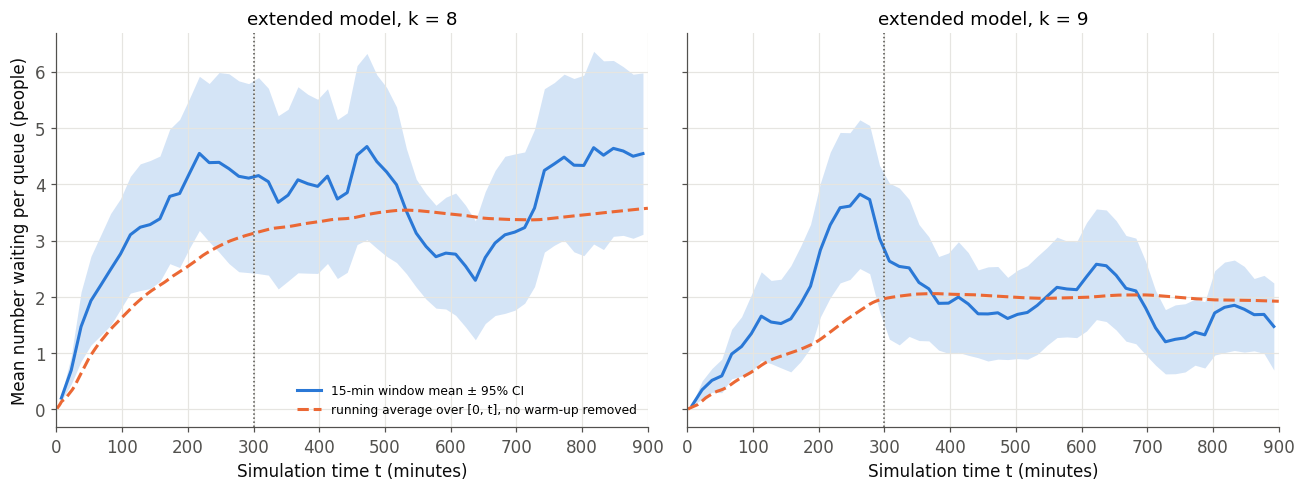

Ensemble mean number waiting per queue, 100 runs (95% CI of the mean):
  k = 8
    [  0, 100) min    1.62 ± 0.55
    [100, 200) min    3.44 ± 0.99
    [200, 300) min    4.30 ± 1.43
    [300, 500) min    4.08 ± 1.29
    [500, 700) min    3.02 ± 0.88
    [700, 900) min    4.28 ± 1.18
  k = 9
    [  0, 100) min    0.67 ± 0.25
    [100, 200) min    1.76 ± 0.81
    [200, 300) min    3.45 ± 1.16
    [300, 500) min    2.03 ± 0.77
    [500, 700) min    2.14 ± 0.61
    [700, 900) min    1.53 ± 0.40


In [30]:
# Same window method as Section 6, at the two station counts closest to the capacity boundary.
# 100 runs rather than the 200 of Section 6: each run here is 900 minutes of the extended model.
N_BOUNDARY_RUNS = 100
BOUNDARY_KS = (8, 9)
boundary_horizon = 3 * PART2_WARMUP
boundary_grid = np.linspace(0, boundary_horizon, int(boundary_horizon) + 1)

boundary = {}
for k in BOUNDARY_KS:
    snapshots, cumulatives = [], []
    for i in range(N_BOUNDARY_RUNS):
        airport = run_simulation(n_stations=k, senior_prob=SENIOR_PROB, run_until=boundary_horizon,
                                 seed=120_000 + 1_000 * k + i, record_history=True)
        snapshot, cumulative = time_average_curves(airport, boundary_grid)
        snapshots.append(snapshot)
        cumulatives.append(cumulative)
    boundary[k] = {'snapshots': np.array(snapshots), 'cumulatives': np.array(cumulatives)}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
window = 15   # minutes; wider than Section 6 because this process moves more slowly
for ax, k in zip(axes, BOUNDARY_KS):
    snaps = boundary[k]['snapshots']
    n_windows = (len(boundary_grid) - 1) // window
    centres = boundary_grid[:-1].reshape(n_windows, window).mean(axis=1) + 0.5
    values = snaps[:, :-1].reshape(N_BOUNDARY_RUNS, n_windows, window).mean(axis=2)
    mean = values.mean(axis=0)
    half = sts.t.ppf(0.975, N_BOUNDARY_RUNS - 1) * values.std(axis=0, ddof=1) / np.sqrt(N_BOUNDARY_RUNS)
    running = boundary[k]['cumulatives'].mean(axis=0)
    ax.fill_between(centres, mean - half, mean + half, color=BLUE, alpha=0.2, linewidth=0)
    ax.plot(centres, mean, color=BLUE, label=f'{window}-min window mean ± 95% CI')
    ax.plot(boundary_grid[1:], running[1:], color=ORANGE, linestyle='--',
            label='running average over [0, t], no warm-up removed')
    ax.axvline(PART2_WARMUP, color=MUTED, linewidth=1, linestyle=':')
    ax.set_title(f'extended model, k = {k}')
    ax.set_xlabel('Simulation time t (minutes)')
    ax.set_xlim(0, boundary_horizon)
axes[0].set_ylabel('Mean number waiting per queue (people)')
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f'Ensemble mean number waiting per queue, {N_BOUNDARY_RUNS} runs (95% CI of the mean):')
blocks = [(0, 100), (100, 200), (200, 300), (300, 500), (500, 700), (700, 900)]
for k in BOUNDARY_KS:
    print(f'  k = {k}')
    for start, stop in blocks:
        mean, half = mean_ci(boundary[k]['snapshots'][:, start:stop].mean(axis=1))
        print(f'    [{start:3d}, {stop:3d}) min   {mean:5.2f} ± {half:4.2f}')


In [ ]:
# Independent replication at k = 9 with 200 new seeds. Is the bump around 200-300 minutes
# in the 100 runs above a real overshoot, or sampling noise from a few extreme runs?
REPLICATION_RUNS = 200
replication = np.array([
    time_average_curves(run_simulation(n_stations=9, senior_prob=SENIOR_PROB, run_until=boundary_horizon,
                                       seed=777_000 + i, record_history=True), boundary_grid)[0]
    for i in range(REPLICATION_RUNS)])
print(f'k = 9, {REPLICATION_RUNS} independent runs: mean number waiting per queue (95% CI of the mean) and median run')
for start, stop in blocks:
    block_values = replication[:, start:stop].mean(axis=1)
    mean, half = mean_ci(block_values)
    print(f'    [{start:3d}, {stop:3d}) min   {mean:5.2f} ± {half:4.2f}   median {np.median(block_values):4.2f}')

# How heavy is the tail? Share of the [200, 300) total that the 5 largest of the original 100 runs carry.
original_block = boundary[9]['snapshots'][:, 200:300].mean(axis=1)
top_five_share = np.sort(original_block)[-5:].sum() / original_block.sum()
print(f'\nOriginal 100 runs at k = 9: the 5 largest runs carry {top_five_share:.0%} of the [200, 300) total.')

k = 9, 200 independent runs: mean number waiting per queue (95% CI of the mean) and median run
    [  0, 100) min    0.65 ± 0.18   median 0.21
    [100, 200) min    1.57 ± 0.41   median 0.39
    [200, 300) min    1.89 ± 0.50   median 0.43
    [300, 500) min    2.23 ± 0.55   median 0.85
    [500, 700) min    2.28 ± 0.49   median 0.77
    [700, 900) min    1.90 ± 0.51   median 0.61

Original 100 runs at k = 9: the 5 largest runs carry 35% of the [200, 300) total.


**Figure 7.** Transient of the extended model at k = 8 and k = 9, averaged over 100 runs that each start from an empty airport. The blue band is the ensemble mean in 15-minute windows, with a 95% confidence interval of that mean. The dashed curve is the running average from t = 0. The dotted line marks the 300-minute warm-up used in the rest of this section.

The first 100 minutes are the empty start and must be discarded: at k = 8 that block is 1.62 ± 0.55 people per queue against 3.0–4.3 later, and at k = 9 it is 0.67 ± 0.25 against 1.5–3.5 later.

At k = 8 the blocks from 100 minutes on overlap. At k = 9 the [200, 300) block (3.45 ± 1.16) sits above [700, 900) (1.53 ± 0.40), which looks like an overshoot. It does not reproduce: in 200 independent runs (the cell above), the mean rises from 0.65 to 1.89 over the first 300 minutes and then levels off (2.23, 2.28, 1.90), with no bump at 200–300 minutes. The bump comes from heavy tails. A few runs with long officer-driven pile-ups dominate each block: the 5 largest of the original 100 runs carry 35% of the [200, 300) total, and the median run is far below the mean in every block (0.43 against 1.89 at [200, 300)). So 100-run means jump around. After 300 minutes, the blocks in both sets of runs overlap and agree with the sweep's day-long mean at k = 9 (1.98 ± 0.39), which is our empirical evidence that a 300-minute warm-up is enough. Heavy tails are also why the sweep averages 50 independent days instead of trusting one long run.


### 8.2 Five analytical scenarios

`mg1_mean_queue_length` is the Pollaczek–Khinchine formula

$$L_q = \frac{\rho^2 (1 + \mathrm{CV}^2)}{2(1 - \rho)}, \qquad
W_q(k) = \frac{\lambda \, E[S^2]}{2\,(k - \lambda E[S])}.$$

The two expressions are the same formula. What changes from one scenario to the next is which service-time moments are substituted for E[S] and E[S^2]. The cell below keeps the regular-screening substitution, which is Layer 1 of the theory report. The cell after it substitutes the other four.

The five scenarios, in the order of the report, are:

1. **Regular.** Base screening only. This is the basic model.
2. **Officer always free.** Additional screening happens, but the officer's waiting time is zero (Layer 2).
3. **M/G/1, case (a).** The officer is an M/G/1 queue, and the delay that blocks a station is replaced by its mean. Variability of that delay is ignored.
4. **M/G/1, case (b).** The same mean delay, but the second moment of the delay comes from Takács' formula. The simulated officer wait is random, so this is the scenario the extended simulation should be compared with.
5. **M/M/1 sensitivity.** The officer delay is replaced by the larger M/M/1 mean, still treated as a constant. This is the report's M/M/1 sensitivity case, not a claim that additional screening is exponential.

Cases (a) and (b) share a capacity threshold near 7.59 stations, so both are defined on the whole sweep. The M/M/1 threshold is near 8.40, so that column is unstable at k = 8. Figures 8 and 9 draw only the regular curve and case (b). The other three stay in the table. Putting all five on the axes would hide the two simulations.

Every queue length in this section is the per-queue length (\lambda/k) W_q. At k = 9, case (b) gives W_q = 15.757 minutes, so a queue holds about 17.51 people and the whole airport holds about 157.57. Those are one quantity in two units. The simulation reports the first.


In [ ]:
def mg1_theory(station_range, arrival_rate=ARRIVAL_RATE, service_distribution=regular_screening):
    """
    Regular-screening baseline: each of k queues is an independent M/G/1 queue
    fed at rate arrival_rate / k, with no join-the-shortest-queue routing and
    no senior officer. This is Layer 1 of the theory report, and only that column.

    Returns
    -------
    (theory_length, theory_wait) : two dicts mapping k to the per-queue mean
        length (Pollaczek–Khinchine) and the mean waiting time (Little's law).
    """
    theory_length, theory_wait = {}, {}
    for k in station_range:
        per_queue_rate = arrival_rate / k
        length = mg1_mean_queue_length(per_queue_rate, service_distribution)
        theory_length[k] = length
        theory_wait[k] = length / per_queue_rate   # Little's law: W_q = L_q / (λ/k)
    return theory_length, theory_wait


theory_length, theory_wait = mg1_theory(STATION_RANGE)


In [ ]:
def pk_from_moments(mean, second, n, lam=ARRIVAL_RATE):
    """
    Mean wait and both queue-length normalizations for one M/G/1 scenario.

    W_q = λ E[S^2] / (2 (n − λ E[S])), which is mg1_mean_queue_length rewritten
    as a waiting time. per_queue is (λ/n) W_q. total is the airport-wide λ W_q.
    """
    capacity = lam * mean
    if n <= capacity:
        return {'wait': np.nan, 'per_queue': np.nan, 'total': np.nan, 'stable': False}
    wait = lam * second / (2 * (n - capacity))
    return {'wait': wait, 'per_queue': (lam / n) * wait, 'total': lam * wait, 'stable': True}


def theory_for_all_models(station_range, lam=ARRIVAL_RATE, p=SENIOR_PROB):
    """
    The five scenarios of the theory report.

    Moments come from the same truncated normals the simulation draws, so this
    cell reproduces the report's table of predicted waits rather than defining a second set of formulas.
    Case (b) uses the Takács second moment of the officer delay. The M/M/1
    column substitutes that scenario's larger mean delay and, as in the report,
    treats the delay as a constant.

    Returns
    -------
    curves : dict
        scenario -> {k: {'wait', 'per_queue', 'total', 'stable'}}
    moments : dict
        scenario -> (E[S], E[S^2]), the pair substituted into Pollaczek–Khinchine.
    """
    b1, b2 = regular_screening.mean(), float(regular_screening.moment(2))
    a1 = senior_screening.mean()
    a2, a3 = float(senior_screening.moment(2)), float(senior_screening.moment(3))

    officer_rate = lam * p
    officer_rho = officer_rate * a1
    if officer_rho >= 1:
        raise ValueError(f'Senior officer is overloaded (ρ_s = {officer_rho:.3f}).')
    # M/G/1 officer delay: mean, and Takács' second moment E[W^2] = 2 E[W]^2 + λ E[S^3] / (3(1−ρ))
    officer_wait = officer_rate * a2 / (2 * (1 - officer_rho))
    officer_wait_second = 2 * officer_wait ** 2 + officer_rate * a3 / (3 * (1 - officer_rho))
    # M/M/1 sensitivity: larger mean delay, inserted as a constant the way the report does
    officer_wait_mm1 = officer_rho * a1 / (1 - officer_rho)

    def effective_moments(wait_mean, wait_second):
        """E[S_eff] and E[S_eff^2] for S_eff = B + I (A + W), with I ~ Bernoulli(p)."""
        mean = b1 + p * (a1 + wait_mean)
        second = (b2
                  + 2 * p * b1 * (a1 + wait_mean)
                  + p * (a2 + 2 * a1 * wait_mean + wait_second))
        return mean, second

    moments = {
        'regular': (b1, b2),
        'officer_free': effective_moments(0.0, 0.0),
        'extended_deterministic': effective_moments(officer_wait, officer_wait ** 2),
        'extended_random': effective_moments(officer_wait, officer_wait_second),
        'mm1': effective_moments(officer_wait_mm1, officer_wait_mm1 ** 2),
    }
    curves = {
        name: {k: pk_from_moments(mean, second, k, lam) for k in station_range}
        for name, (mean, second) in moments.items()
    }
    return curves, moments


# Cover the report's table (k = 6, 7) and enough k to turn a 1-minute target into a station count.
theory_curves, theory_moments = theory_for_all_models(range(6, 41))

for k in STATION_RANGE:
    regular_wait = theory_curves['regular'][k]['wait']
    check(abs(regular_wait - theory_wait[k]) < 1e-9,
          f'regular column matches mg1_theory at k = {k}')

# The report's table of predicted waits, rounded to three decimals. This locks the notebook to that table.
table2_at_9 = {
    'regular': 0.348, 'officer_free': 0.978, 'extended_deterministic': 10.061,
    'extended_random': 15.757, 'mm1': 38.097,
}
for name, expected in table2_at_9.items():
    got = theory_curves[name][9]['wait']
    check(abs(got - expected) < 5e-4, f'{name} at k = 9 is {got:.3f}, report says {expected:.3f}')

SCENARIO_LABELS = [
    ('regular', 'Regular'),
    ('officer_free', 'Officer free'),
    ('extended_deterministic', 'M/G/1 (a)'),
    ('extended_random', 'M/G/1 (b)'),
    ('mm1', 'M/M/1'),
]
print('Mean waiting time W_q (minutes). "unstable" means k is below λ E[S] for that scenario.')
print(f'{"k":>4}  ' + '  '.join(f'{label:>12}' for _, label in SCENARIO_LABELS))
for k in range(6, 17):
    cells_txt = []
    for name, _ in SCENARIO_LABELS:
        row = theory_curves[name][k]
        cells_txt.append(f'{"unstable":>12}' if not row['stable'] else f'{row["wait"]:12.3f}')
    print(f'{k:4d}  ' + '  '.join(cells_txt))

per_queue_9 = theory_curves['extended_random'][9]['per_queue']
total_9 = theory_curves['extended_random'][9]['total']
print(f'\nCase (b) at k = 9: per queue {per_queue_9:.2f} people, airport-wide total {total_9:.2f} people.')
print('The simulation and Figures 8–9 use the per-queue number. The report\'s appendix table of queue lengths prints the total.')


PASS  regular column matches mg1_theory at k = 8
PASS  regular column matches mg1_theory at k = 9
PASS  regular column matches mg1_theory at k = 10
PASS  regular column matches mg1_theory at k = 11
PASS  regular column matches mg1_theory at k = 12
PASS  regular column matches mg1_theory at k = 13
PASS  regular column matches mg1_theory at k = 14
PASS  regular column matches mg1_theory at k = 15
PASS  regular column matches mg1_theory at k = 16
PASS  regular at k = 9 is 0.348, report says 0.348
PASS  officer_free at k = 9 is 0.978, report says 0.978
PASS  extended_deterministic at k = 9 is 10.061, report says 10.061
PASS  extended_random at k = 9 is 15.757, report says 15.757
PASS  mm1 at k = 9 is 38.097, report says 38.097
Mean waiting time W_q (minutes). "unstable" means k is below λ E[S] for that scenario.
   k       Regular  Officer free     M/G/1 (a)     M/G/1 (b)         M/M/1
   6         1.401        14.316      unstable      unstable      unstable
   7         0.698         2.5

### 8.3 Average traveler waiting time

The dashed gray curve is the regular M/G/1 baseline. The dash-dot gray curve is case (b), the extended model whose officer delay is random. The markers with error bars are the two simulations. The right panel uses the same four curves on a vertical scale set by the simulations, because case (b) at k = 8 is 54.2 minutes and would otherwise compress everything else onto the axis.


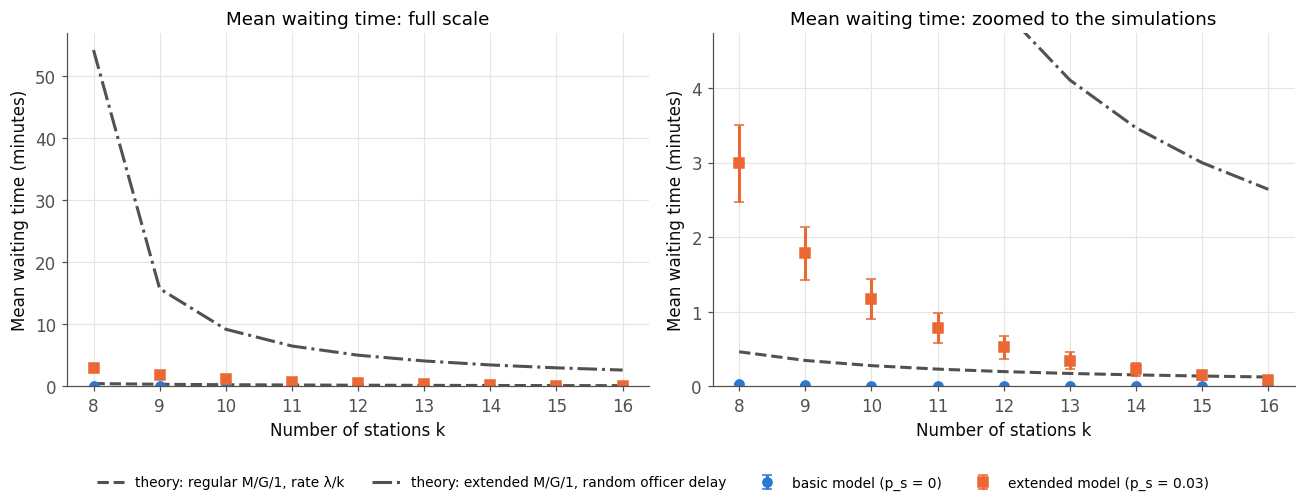

In [34]:
# The slow cell: 9 station counts, 2 models, 50 days, common random numbers.
basic_sweep = sweep_stations(STATION_RANGE, senior_prob=0.0)
full_sweep = sweep_stations(STATION_RANGE, senior_prob=SENIOR_PROB)

ks = list(STATION_RANGE)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax in axes:
    ax.plot(ks, [theory_wait[k] for k in ks], color=MUTED, linestyle='--',
            label='theory: regular M/G/1, rate λ/k')
    ax.plot(ks, [theory_curves['extended_random'][k]['wait'] for k in ks], color=MUTED, linestyle='-.',
            label='theory: extended M/G/1, random officer delay')
    for label, sweep, color, marker in [('basic model (p_s = 0)', basic_sweep, BLUE, 'o'),
                                         ('extended model (p_s = 0.03)', full_sweep, ORANGE, 's')]:
        means = [sweep['mean_waiting_time'][k][0] for k in ks]
        halves = [sweep['mean_waiting_time'][k][1] for k in ks]
        ax.errorbar(ks, means, yerr=halves, color=color, marker=marker, capsize=3, linestyle='none', label=label)
    ax.set_xlabel('Number of stations k')
    ax.set_ylabel('Mean waiting time (minutes)')
sim_top = max(full_sweep['mean_waiting_time'][k][0] + full_sweep['mean_waiting_time'][k][1] for k in ks)
axes[0].set_title('Mean waiting time: full scale')
axes[1].set_title('Mean waiting time: zoomed to the simulations')
axes[0].set_ylim(bottom=0)
axes[1].set_ylim(0, sim_top * 1.35)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=4, fontsize=9)
plt.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()


**Figure 8.** Mean traveler waiting time against k. Points are 50 independent days; the bars are 95% confidence intervals of the mean. The right panel is the same figure with the vertical axis set by the simulations. Case (b) leaves the top of that panel at the small values of k.

The regular M/G/1 curve is the wrong benchmark for the extended simulation. At k = 8 it predicts 0.465 minutes. The basic simulation, on the same seeds, is 0.035 ± 0.001 minutes. Join-the-shortest-queue routing sends each arrival to a free station, and the independent-queue formula has no such mechanism, so the formula sits above the basic model. It sits below the extended simulation, which at k = 8 waits 2.988 ± 0.518 minutes. An officer delay is not in the regular formula, so that formula cannot describe the extended model.

The comparison that matches the extended simulation is case (b). At k = 8 it predicts 54.2 minutes, against 2.99 in the simulation. At k = 12 the same pair is 5.04 against 0.522 ± 0.155. At k = 16 it is 2.64 against 0.093 ± 0.041. The gap narrows and does not close inside this range, and it is widest at k = 8, near the approximate capacity boundary. Section 8.6 separates the causes of this gap. Case (a), which drops the variance of the officer delay, is lower than case (b) and still far above the simulation: 34.6 minutes against 2.99 at k = 8. The M/M/1 column is higher again, and it is not stable at k = 8.


### 8.4 Average queue length

Queue length is the same congestion counted in people. Because the simulation averages across lines, the case (b) curve below is the per-queue length (\lambda/k) W_q, not the airport-wide total. Little's law then says this figure has the same shape as Figure 8.


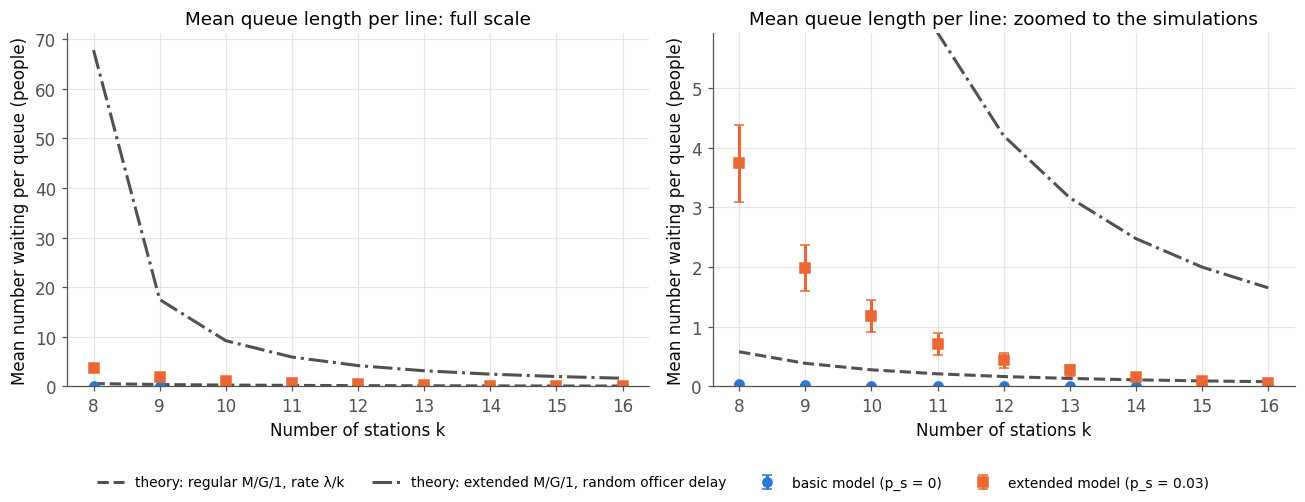

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax in axes:
    ax.plot(ks, [theory_length[k] for k in ks], color=MUTED, linestyle='--',
            label='theory: regular M/G/1, rate λ/k')
    ax.plot(ks, [theory_curves['extended_random'][k]['per_queue'] for k in ks], color=MUTED, linestyle='-.',
            label='theory: extended M/G/1, random officer delay')
    for label, sweep, color, marker in [('basic model (p_s = 0)', basic_sweep, BLUE, 'o'),
                                         ('extended model (p_s = 0.03)', full_sweep, ORANGE, 's')]:
        means = [sweep['mean_queue_length'][k][0] for k in ks]
        halves = [sweep['mean_queue_length'][k][1] for k in ks]
        ax.errorbar(ks, means, yerr=halves, color=color, marker=marker, capsize=3, linestyle='none', label=label)
    ax.set_xlabel('Number of stations k')
    ax.set_ylabel('Mean number waiting per queue (people)')
sim_top = max(full_sweep['mean_queue_length'][k][0] + full_sweep['mean_queue_length'][k][1] for k in ks)
axes[0].set_title('Mean queue length per line: full scale')
axes[1].set_title('Mean queue length per line: zoomed to the simulations')
axes[0].set_ylim(bottom=0)
axes[1].set_ylim(0, sim_top * 1.35)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=4, fontsize=9)
plt.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()


**Figure 9.** Mean number of travelers waiting per queue against k, from the same 50 days as Figure 8. The right panel is zoomed to the simulations.

The shape matches the waiting time, on the per-queue scale (λ/k)·W_q. At k = 8 the regular formula gives 0.581 people per queue, the basic simulation gives 0.043 ± 0.001, and the extended simulation gives 3.736 ± 0.645. Case (b) at the same k is (10/8) × 54.225 = 67.8 people per queue. At k = 9, case (b) is 17.51 people per queue and the simulation is 1.981 ± 0.389. The airport-wide total at that point is 157.57 people, which is what the report's appendix table of queue lengths prints. That total is a different unit, and it is not what the simulated points measure. By k = 16 the extended simulation is down to 0.058 ± 0.026 per queue, against a case (b) value of about 1.65.


### 8.5 Maximum queue length

Pollaczek–Khinchine gives a mean. The maximum of a queue over a finite day does not have a closed form in this model, and the theory report does not claim one. It states three mechanisms instead. The figure reports the simulation. The cell after it tests the three mechanisms.

The plotted number is `max_queue_length` from `Airport.results`: the largest number waiting in any single line during the measured day. Each point is the mean of that daily worst line over 50 days, with a 95% confidence interval of the mean. It is not the maximum of the total number waiting in the airport.


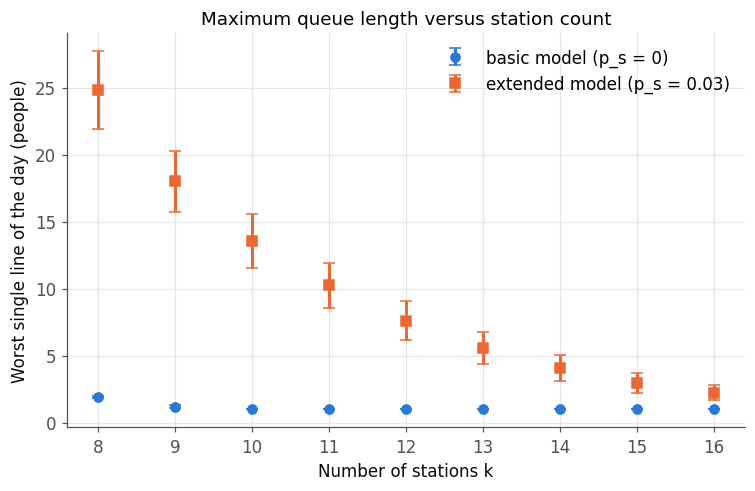

In [36]:
fig, ax = plt.subplots(figsize=(7, 4.6))
for label, sweep, color, marker in [('basic model (p_s = 0)', basic_sweep, BLUE, 'o'),
                                     ('extended model (p_s = 0.03)', full_sweep, ORANGE, 's')]:
    means = [sweep['max_queue_length'][k][0] for k in ks]
    halves = [sweep['max_queue_length'][k][1] for k in ks]
    ax.errorbar(ks, means, yerr=halves, color=color, marker=marker, capsize=4, linestyle='none', label=label)
ax.set_xlabel('Number of stations k')
ax.set_ylabel('Worst single line of the day (people)')
ax.set_title('Maximum queue length versus station count')
ax.legend()
plt.tight_layout()
plt.show()


In [37]:
# --- The theory report's three mechanisms for the maximum. None of these is a closed form for the daily maximum. ---

# (1) Heavy traffic: upper quantiles scale like ρ(1+CV^2)/(1−ρ), so the worst line should
#     fall steeply once k clears the threshold, and it should be much larger than the mean
#     while CV^2 of the effective service time is several times one.
mean_b, second_b = theory_moments['extended_random']
cv2_b = (second_b - mean_b ** 2) / mean_b ** 2
print(f'Case (b): E[S] = {mean_b:.3f} min, CV^2 = {cv2_b:.2f} (report: 6.71)')
print(f'{"k":>4}  {"Kingman":>8}  {"sim mean q":>12}  {"sim worst line":>16}  {"worst/mean":>10}')
for k in STATION_RANGE:
    rho = ARRIVAL_RATE * mean_b / k
    kingman = rho * (1 + cv2_b) / (1 - rho)
    q_mean, q_half = full_sweep['mean_queue_length'][k]
    max_mean, max_half = full_sweep['max_queue_length'][k]
    print(f'{k:4d}  {kingman:8.1f}  {q_mean:6.2f} ± {q_half:4.2f}  {max_mean:8.2f} ± {max_half:5.2f}  '
          f'{max_mean / q_mean:10.1f}')

# (2) Below the threshold the backlog should grow about linearly, at λ − k/E[S_eff],
#     so the daily maximum is a property of the horizon rather than of a stationary distribution.
#     k = 6 grows in Section 7.4. For k = 7 the formula predicts growth, while the
#     slope below does not by itself prove stability or instability.
print('\nPredicted drift of the total number waiting, λ − k/E[S_eff] (people per minute):')
DRIFT_RUNS, DRIFT_MINUTES = 30, 1000
drift_grid = np.linspace(0, DRIFT_MINUTES, DRIFT_MINUTES + 1)
from scipy.optimize import brentq


def throughput_consistent_drift(k, lam=ARRIVAL_RATE, p=SENIOR_PROB):
    """
    Predicted growth rate of the total backlog, with the officer's load kept consistent.

    λ − k/E[S_eff] assumes the officer still receives all λ·p referrals per minute.
    When k stations cannot keep up, only a throughput θ < λ gets through, so the
    officer receives p·θ referrals and waits less. We solve θ·h(θ) = k, where
    h(θ) = E[B] + p(E[A] + W_s(pθ)) and W_s is the M/G/1 officer wait at rate pθ.
    The backlog then grows at λ − θ. If k stations can handle λ, the drift is λ − k/h(λ) ≤ 0.
    """
    def occupancy(throughput):
        referral_rate = p * throughput
        officer_wait = mg1_mean_queue_length(referral_rate, senior_screening) / referral_rate
        return regular_screening.mean() + p * (senior_screening.mean() + officer_wait)
    if lam * occupancy(lam) <= k:
        return lam - k / occupancy(lam)
    throughput = brentq(lambda t: t * occupancy(t) - k, 1e-6, lam)
    return lam - throughput


for k in (6, 7, 8):
    predicted = ARRIVAL_RATE - k / mean_b
    consistent = throughput_consistent_drift(k)
    totals = []
    for i in range(DRIFT_RUNS):
        airport = run_simulation(n_stations=k, senior_prob=SENIOR_PROB, run_until=DRIFT_MINUTES,
                                 seed=130_000 + 100 * k + i, record_history=True)
        snapshot, _ = time_average_curves(airport, drift_grid)
        totals.append(snapshot * k)
    mean_path = np.mean(totals, axis=0)
    slope = np.polyfit(drift_grid[300:], mean_path[300:], 1)[0]
    print(f'  k = {k}: steady-state formula {predicted:+.2f} /min,  throughput-consistent {consistent:+.2f} /min,  '
          f'simulated slope from t = 300 to {DRIFT_MINUTES}: {slope:+.2f} /min')

# (3) One officer can freeze several stations at once, so the lines move together.
#     The blocked-station count is compared with λ_s (E[W_s] + E[A]) = 2.58 under A2.
#     Pairwise correlation of the queue lengths is reported too. A high correlation is
#     consistent with the shared officer and with shortest-queue routing; this run does
#     not separate the two.
officer_wait_mean = (mean_b - regular_screening.mean()) / SENIOR_PROB - senior_screening.mean()
predicted_blocked = ARRIVAL_RATE * SENIOR_PROB * (officer_wait_mean + senior_screening.mean())
BLOCK_RUNS, BLOCK_WARMUP, BLOCK_WINDOW = 20, 300, 600
block_grid = np.arange(BLOCK_WARMUP, BLOCK_WARMUP + BLOCK_WINDOW + 1)
blocked_means, pair_corrs = [], []
for i in range(BLOCK_RUNS):
    airport = run_simulation(n_stations=8, senior_prob=SENIOR_PROB, run_until=BLOCK_WARMUP + BLOCK_WINDOW,
                             seed=140_000 + i, record_history=True)
    lengths, blocked = [], []
    for queue in airport.queues:
        times = np.array([h[0] for h in queue.history])
        idx = np.searchsorted(times, block_grid, side='right') - 1
        lengths.append(np.array([h[1] for h in queue.history])[idx])
        blocked.append(np.array([h[2] for h in queue.history])[idx] == Queue.BLOCKED)
    blocked_means.append(np.mean(np.sum(blocked, axis=0)))
    correlation = np.corrcoef(np.array(lengths))
    pair_corrs.append(correlation[np.triu_indices(8, 1)].mean())
blocked_ci, corr_ci = mean_ci(blocked_means), mean_ci(pair_corrs)
print(f'\nAt k = 8, time-average number of stations blocked (waiting for or with the officer):')
print(f'  simulation {blocked_ci[0]:.2f} ± {blocked_ci[1]:.2f}    '
      f'A2 prediction λ_s (E[W_s] + E[A]) = {predicted_blocked:.2f}')
print(f'  mean pairwise correlation of the k queue lengths: {corr_ci[0]:.2f} ± {corr_ci[1]:.2f}')


Case (b): E[S] = 0.759 min, CV^2 = 6.71 (report: 6.71)
   k   Kingman    sim mean q    sim worst line  worst/mean
   8     142.9    3.74 ± 0.64     24.82 ±  2.88         6.6
   9      41.5    1.98 ± 0.39     18.02 ±  2.27         9.1
  10      24.3    1.18 ± 0.26     13.58 ±  2.02        11.5
  11      17.2    0.71 ± 0.18     10.24 ±  1.71        14.4
  12      13.3    0.44 ± 0.13      7.62 ±  1.45        17.5
  13      10.8    0.27 ± 0.09      5.58 ±  1.18        20.9
  14       9.1    0.16 ± 0.06      4.10 ±  0.96        25.1
  15       7.9    0.10 ± 0.04      2.96 ±  0.77        30.0
  16       7.0    0.06 ± 0.03      2.24 ±  0.57        38.3

Predicted drift of the total number waiting, λ − k/E[S_eff] (people per minute):
  k = 6: steady-state formula +2.10 /min,  throughput-consistent +1.28 /min,  simulated slope from t = 300 to 1000: +0.72 /min
  k = 7: steady-state formula +0.78 /min,  throughput-consistent +0.41 /min,  simulated slope from t = 300 to 1000: -0.00 /min
  k = 8: s

**Figure 10.** Mean of the daily worst single line against k, with 95% confidence intervals of the mean. Basic model in blue, extended model in orange. This is one line, not the airport-wide total.

The theory report names three mechanisms and does not give a formula for this curve. The printout tests them one at a time.

1. **The worst line falls steeply, and it stays much larger than the mean.** The extended model's worst line falls from 24.82 ± 2.88 people at k = 8 to 2.24 ± 0.57 at k = 16. Over the same range the mean queue falls from 3.74 to 0.06, so the worst line is 6.6 times the mean at k = 8 and about 38 times the mean at k = 16: the mean drops faster than the maximum. Kingman's factor ρ(1+CV²)/(1−ρ), with the case (b) value CV² = 6.71, falls from 143 to 7 over the same k. It tracks the direction of the drop. It does not predict the headcount, and 143 is not 25. The basic model is a different regime: from k = 10 upward its worst line is 1.00 ± 0.00 in all 50 days.

2. **Below the approximate threshold, the backlog grows.** The steady-state formula λ − k/E[S_eff] gives +2.10 people per minute at k = 6 and +0.78 at k = 7. That formula assumes the officer still receives all λp = 0.3 referrals per minute, which cannot happen when the stations are overloaded: fewer travelers get through, so there are fewer referrals and shorter officer waits. Solving for the throughput consistently gives +1.28 at k = 6 and +0.41 at k = 7. The simulated slopes from t = 300 to 1,000 minutes are +0.72 and about 0.00. The consistent prediction halves the gap at k = 6; the rest most likely comes from the approximate M/G/1 officer model (A2). At k = 7 a growth of 0.41 per minute is not visible within 1,000 minutes, so its stability stays unresolved. k = 8 wanders without a trend. Below the threshold, the daily maximum therefore depends on the length of the day, not on a stationary distribution.

3. **The officer freezes several stations at once.** At k = 8 the time-average number of blocked stations is 1.91 ± 0.20. Little's law under A2 predicts λ_s(E[W_s]+E[A]) = 2.58, which lies outside that interval. The mean pairwise correlation of the eight queue lengths is 0.96 ± 0.03, so the lines move together. That correlation is consistent with a shared senior officer, and it is also consistent with shortest-queue routing. A single-queue formula has no term for a shock shared across lines. The blocked count depends on the officer's own queue rather than on how travelers pick lines, so the shortfall is a direct measurement: 1.91 blocked stations at 0.3 referrals per minute means a referred traveler holds a station for about 6.4 minutes, so the wait for the officer is about 3.8 minutes rather than the 6.0 the M/G/1 formula predicts. The officer model overestimates the officer's queue.


### 8.6 Where the gap between theory and simulation comes from

Every analytical scenario overestimates the simulated waits. The theory differs from the simulation in two places:

1. **Routing (approximation A1).** The formulas treat each line as an independent M/G/1 queue fed at rate λ/k. That is exact only if each traveler picks a line **at random**. The simulation sends each traveler to the shortest line.
2. **The officer (approximations A2 and A3).** The formulas treat the officer as an M/G/1 queue with Poisson referrals, which ignores that a blocked station cannot send a new referral.

To separate the two, we rerun the simulation with only the routing rule changed. `RandomRoutingAirport` inherits everything from `Airport` and overrides one method, so each traveler joins a uniformly random line. Any remaining gap between that simulation and the formula is due to the officer approximations. The gap between random and shortest-queue routing is due to routing.

We also add a **lower** benchmark: one pooled line feeding all k stations (M/G/c). Shortest-queue routing that prefers idle stations behaves much like a pooled line, except that travelers cannot switch lines later. We use the Erlang C formula from class with the Allen–Cunneen correction for general service times,

$$W_q^{M/G/c} \approx C\!\left(c, \lambda E[S]\right) \frac{E[S]}{c - \lambda E[S]} \cdot \frac{1 + \mathrm{CV}_S^2}{2}.$$

Basic model, mean wait (minutes)
  k  M/G/1 theory    random routing    shortest queue  pooled M/G/c
  8         0.465     0.464 ± 0.007     0.035 ± 0.001        0.0156
 10         0.279     0.281 ± 0.004     0.006 ± 0.000        0.0020
 12         0.199     0.200 ± 0.002     0.001 ± 0.000        0.0002
 14         0.155     0.155 ± 0.002     0.000 ± 0.000        0.0000
 16         0.127     0.126 ± 0.002     0.000 ± 0.000        0.0000

Extended model, mean wait (minutes)
  k  case (b)  case (a)    random routing    shortest queue  pooled, (b)  routing factor
  8     54.22     34.62      7.74 ± 1.21     2.988 ± 0.518        6.005             2.6
 10      9.22      5.89      3.84 ± 0.62     1.174 ± 0.265        0.393             3.3
 12      5.04      3.22      2.67 ± 0.45     0.522 ± 0.155        0.068             5.1
 14      3.47      2.21      2.10 ± 0.37     0.228 ± 0.083        0.012             9.2
 16      2.64      1.69      1.70 ± 0.29     0.093 ± 0.041        0.002          

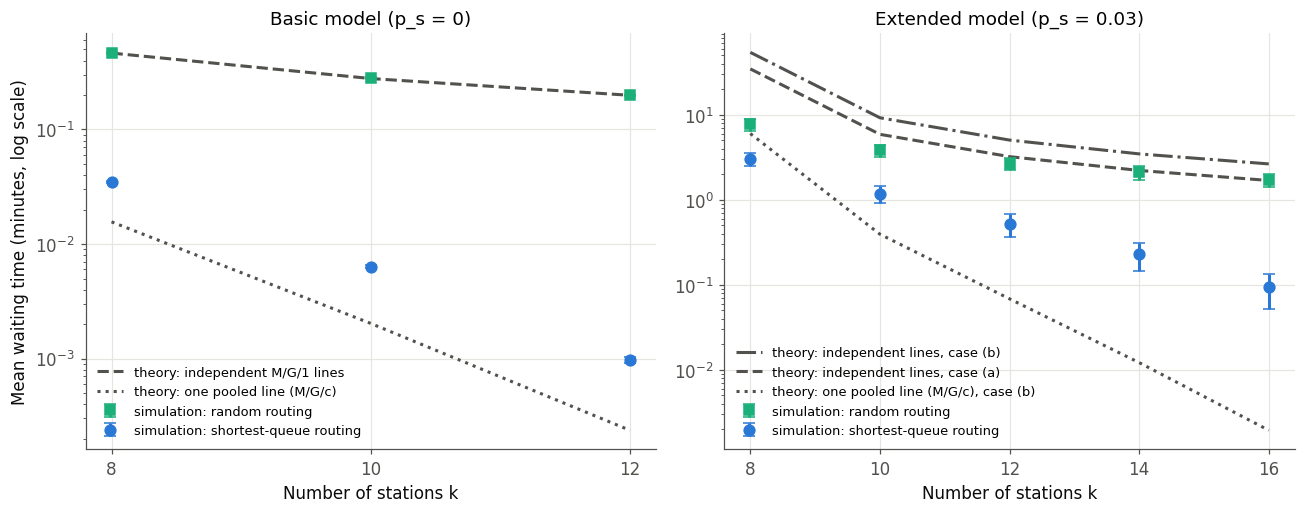

In [38]:
import math


class RandomRoutingAirport(Airport):
    """
    An Airport in which each arriving traveler joins a uniformly random line.

    Used only to test approximation A1. Under random routing, each line receives an
    independent Poisson stream of rate λ/k, which is exactly the independent M/G/1
    assumption of the theory. Routing draws come from their own generator, so arrivals
    and service times are unchanged for matched seeds.
    """

    def __init__(self, n_stations, arrival_distribution, service_distribution,
                 senior_prob, senior_distribution, seed, **options):
        super().__init__(n_stations, arrival_distribution, service_distribution,
                         senior_prob, senior_distribution, seed, **options)
        self.routing_rng = np.random.default_rng([seed, 7])

    def add_traveler(self, schedule):
        """A traveler arrives and joins a random line; the next arrival is scheduled."""
        self.n_arrivals += 1
        chosen = self.queues[self.routing_rng.integers(len(self.queues))]
        if self.routing_log is not None:
            self.routing_log.append(chosen.queue_id)
        chosen.add_traveler(schedule)
        schedule.add_event_after(self.arrival_stream.draw(), self.add_traveler)


def erlang_c(servers, offered_load):
    """Erlang C: probability that an arrival has to wait in an M/M/c queue (offered load r = λE[S])."""
    below = sum(offered_load ** j / math.factorial(j) for j in range(servers))
    top = offered_load ** servers / math.factorial(servers) / (1 - offered_load / servers)
    return top / (below + top)


def pooled_mgc_wait(mean, second, servers, lam=ARRIVAL_RATE):
    """Allen–Cunneen approximation of the M/G/c mean wait for one pooled line (minutes)."""
    offered_load = lam * mean
    if offered_load >= servers:
        return np.nan
    cv2 = (second - mean ** 2) / mean ** 2
    return erlang_c(servers, offered_load) * mean / (servers - offered_load) * (1 + cv2) / 2


ROUTING_KS = (8, 10, 12, 14, 16)
ROUTING_TRIALS = 30          # same seeds as the main sweep (common random numbers)
random_routing = {}
for model, p_s in [('basic', 0.0), ('extended', SENIOR_PROB)]:
    for k in ROUTING_KS:
        trials = run_trials(ROUTING_TRIALS, base_seed=PART2_BASE_SEED, n_stations=k, senior_prob=p_s,
                            warmup=PART2_WARMUP, run_until=PART2_WARMUP + PART2_WINDOW,
                            airport_class=RandomRoutingAirport)
        random_routing[model, k] = mean_ci(trials['mean_waiting_time'])

# Tables: theory, random routing, shortest-queue routing, pooled line
print('Basic model, mean wait (minutes)')
print(f'{"k":>3} {"M/G/1 theory":>13} {"random routing":>17} {"shortest queue":>17} {"pooled M/G/c":>13}')
for k in ROUTING_KS:
    rr, sq = random_routing['basic', k], basic_sweep['mean_waiting_time'][k]
    print(f'{k:>3} {theory_curves["regular"][k]["wait"]:>13.3f} {rr[0]:>9.3f} ± {rr[1]:.3f} '
          f'{sq[0]:>9.3f} ± {sq[1]:.3f} {pooled_mgc_wait(*theory_moments["regular"], k):>13.4f}')

print('\nExtended model, mean wait (minutes)')
print(f'{"k":>3} {"case (b)":>9} {"case (a)":>9} {"random routing":>17} {"shortest queue":>17} {"pooled, (b)":>12} {"routing factor":>15}')
for k in ROUTING_KS:
    rr, sq = random_routing['extended', k], full_sweep['mean_waiting_time'][k]
    print(f'{k:>3} {theory_curves["extended_random"][k]["wait"]:>9.2f} {theory_curves["extended_deterministic"][k]["wait"]:>9.2f} '
          f'{rr[0]:>9.2f} ± {rr[1]:.2f} {sq[0]:>9.3f} ± {sq[1]:.3f} '
          f'{pooled_mgc_wait(*theory_moments["extended_random"], k):>12.3f} {rr[0] / sq[0]:>15.1f}')

# Figure 11
fig, (ax_basic, ax_ext) = plt.subplots(1, 2, figsize=(12, 4.8))
basic_ks = [k for k in ROUTING_KS if k <= 12]     # beyond k = 12 the basic waits are below 0.001 min
dense_basic = np.arange(8, 12.01, 0.1)
ax_basic.plot(basic_ks, [theory_curves['regular'][k]['wait'] for k in basic_ks], color=MUTED, linestyle='--',
              label='theory: independent M/G/1 lines')
ax_basic.plot(basic_ks, [pooled_mgc_wait(*theory_moments['regular'], k) for k in basic_ks], color=MUTED, linestyle=':',
              label='theory: one pooled line (M/G/c)')
ext_theory = [('extended_random', '-.', 'theory: independent lines, case (b)'),
              ('extended_deterministic', '--', 'theory: independent lines, case (a)')]
for name, style, label in ext_theory:
    ax_ext.plot(ROUTING_KS, [theory_curves[name][k]['wait'] for k in ROUTING_KS], color=MUTED, linestyle=style, label=label)
ax_ext.plot(ROUTING_KS, [pooled_mgc_wait(*theory_moments['extended_random'], k) for k in ROUTING_KS],
            color=MUTED, linestyle=':', label='theory: one pooled line (M/G/c), case (b)')
for ax, model, ks_used, sweep in [(ax_basic, 'basic', basic_ks, basic_sweep), (ax_ext, 'extended', ROUTING_KS, full_sweep)]:
    rr_mean = np.array([random_routing[model, k][0] for k in ks_used])
    rr_half = np.array([random_routing[model, k][1] for k in ks_used])
    sq_mean = np.array([sweep['mean_waiting_time'][k][0] for k in ks_used])
    sq_half = np.array([sweep['mean_waiting_time'][k][1] for k in ks_used])
    for means, halves, color, marker, label in [(rr_mean, rr_half, AQUA, 's', 'simulation: random routing'),
                                                (sq_mean, sq_half, BLUE, 'o', 'simulation: shortest-queue routing')]:
        lower = np.minimum(halves, 0.9 * means)       # keep error bars positive on the log axis
        ax.errorbar(ks_used, means, yerr=[lower, halves], color=color, marker=marker, markersize=7,
                    capsize=4, linestyle='none', label=label)
    ax.set_yscale('log')
    ax.set_xlabel('Number of stations k')
    ax.set_xticks(ks_used)
ax_basic.set_ylabel('Mean waiting time (minutes, log scale)')
ax_basic.set_title('Basic model (p_s = 0)')
ax_ext.set_title(f'Extended model (p_s = {SENIOR_PROB})')
ax_basic.legend(fontsize=8.5, loc='lower left')
ax_ext.legend(fontsize=8.5, loc='lower left')
plt.tight_layout()
plt.show()

**Figure 11.** Mean waiting time against k on a log scale, for theory and for two versions of the simulation that differ only in routing (30 days each, same seeds as the main sweep; bars are 95% confidence intervals of the mean). Left: basic model, shown up to k = 12 because beyond that the waits fall below 0.001 minutes. Right: extended model. Exact values are in the tables printed above.

**Routing explains the basic-model gap completely.** With random routing, the basic simulation matches the independent M/G/1 formula at every k (about 0.46 against 0.465 minutes at k = 8, and about 0.126 against 0.127 at k = 16). The formula is right for the system it describes. The 13-fold gap in Figure 8 is entirely due to shortest-queue routing, whose simulated wait (0.035 minutes at k = 8) lies between the random-routing value and the pooled-line benchmark (about 0.016).

**In the extended model, routing is also the largest factor.** At k = 10 the waits step down from case (b), about 9.2 minutes, to case (a), about 5.9, to the random-routing simulation, about 3.8, to the shortest-queue simulation, 1.17. Random routing waits roughly 3 times longer than shortest-queue routing at k = 10, rising to more than 15 times at k = 16, because a shortest-queue traveler almost never joins a line whose station is blocked. The officer approximations account for the rest. Case (a) comes close to the random-routing simulation for k ≥ 14. Near the threshold (k = 8: case (a) 34.6 against roughly 8 for random routing) both theory cases blow up too early, because the M/G/1 officer model overstates the officer's wait (Section 8.5, point 3). Case (b) is too high throughout.

### 8.7 Recommendation

A service-level target is a policy choice. Nothing in the arrival process picks it. The example used here is a mean wait at or below 1 minute.

For the simulation, the rule is the smallest k, inside the tested range k = 8 to 16, whose **95% confidence interval for the mean** lies entirely at or below 1 minute. That interval is uncertainty about the mean we estimated from 50 days. Requiring the upper end to clear the target keeps the estimated mean on the safe side of the target. It does **not** mean that 95% of days have a wait below 1 minute. A guarantee about individual days would be a prediction interval, or a high quantile of the daily distribution, and we have not estimated either. The k this rule returns is a simulated choice for this target inside this range. It is not a proven global optimum.

For the theory, there is no sampling interval. The station count is the smallest k whose Pollaczek–Khinchine mean, under that scenario's approximations, is at or below 1 minute. Comparing the two answers is the point of having both.


In [39]:
TARGET_WAIT = 1.0   # minutes; an example target, not a consequence of the model


def minimum_k_for_target(sweep, target, station_range=STATION_RANGE, use_upper_bound=True):
    """
    Smallest k in station_range whose estimate of the mean waiting time lies at or below target.

    The returned k is the simulated choice inside that range. It is not a proven global optimum.

    use_upper_bound=True requires mean + half_width <= target. The half-width is
    the 95% confidence interval of the mean, so this guards against uncertainty in
    the estimated mean. It is not a claim about the fraction of days that meet target.
    """
    for k in station_range:
        mean, half = sweep['mean_waiting_time'][k]
        estimate = mean + half if use_upper_bound else mean
        if estimate <= target:
            return k
    return None


def minimum_k_from_theory(mean, second, target, k_max=80):
    """Smallest k whose Pollaczek–Khinchine mean wait is at or below target."""
    for k in range(1, k_max + 1):
        row = pk_from_moments(mean, second, k)
        if row['stable'] and row['wait'] <= target:
            return k
    return None


recommended_k = minimum_k_for_target(full_sweep, TARGET_WAIT, use_upper_bound=True)
recommended_k_mean = minimum_k_for_target(full_sweep, TARGET_WAIT, use_upper_bound=False)
print(f'Simulated extended model, mean wait <= {TARGET_WAIT:.1f} min:            k = {recommended_k_mean}')
print(f'Same, but the upper end of the 95% CI of the mean <= {TARGET_WAIT:.1f}: k = {recommended_k}')
print()
print(f'Theory, smallest k with W_q <= {TARGET_WAIT:.1f} min under each scenario:')
for name, label in SCENARIO_LABELS:
    k_theory = minimum_k_from_theory(*theory_moments[name], TARGET_WAIT)
    print(f'  {label:<14} k = {k_theory}')
print()
print('Basic model, same seeds (per queue):')
for k in STATION_RANGE:
    wait_mean, wait_half = basic_sweep['mean_waiting_time'][k]
    length_mean, length_half = basic_sweep['mean_queue_length'][k]
    max_mean, max_half = basic_sweep['max_queue_length'][k]
    print(f'k = {k:>2}   wait {wait_mean:6.3f} ± {wait_half:5.3f} min   '
          f'queue {length_mean:6.3f} ± {length_half:5.3f} people   '
          f'worst line {max_mean:6.2f} ± {max_half:5.2f} people')
print()
print('Extended model:')
for k in STATION_RANGE:
    wait_mean, wait_half = full_sweep['mean_waiting_time'][k]
    length_mean, length_half = full_sweep['mean_queue_length'][k]
    max_mean, max_half = full_sweep['max_queue_length'][k]
    print(f'k = {k:>2}   wait {wait_mean:6.3f} ± {wait_half:5.3f} min   '
          f'queue {length_mean:6.3f} ± {length_half:5.3f} people   '
          f'worst line {max_mean:6.2f} ± {max_half:5.2f} people')


Simulated extended model, mean wait <= 1.0 min:            k = 11
Same, but the upper end of the 95% CI of the mean <= 1.0: k = 11

Theory, smallest k with W_q <= 1.0 min under each scenario:
  Regular        k = 7
  Officer free   k = 9
  M/G/1 (a)      k = 22
  M/G/1 (b)      k = 30
  M/M/1          k = 32

Basic model, same seeds (per queue):
k =  8   wait  0.035 ± 0.001 min   queue  0.043 ± 0.001 people   worst line   1.90 ±  0.09 people
k =  9   wait  0.015 ± 0.000 min   queue  0.017 ± 0.000 people   worst line   1.18 ±  0.11 people
k = 10   wait  0.006 ± 0.000 min   queue  0.006 ± 0.000 people   worst line   1.00 ±  0.00 people
k = 11   wait  0.003 ± 0.000 min   queue  0.002 ± 0.000 people   worst line   1.00 ±  0.00 people
k = 12   wait  0.001 ± 0.000 min   queue  0.001 ± 0.000 people   worst line   1.00 ±  0.00 people
k = 13   wait  0.000 ± 0.000 min   queue  0.000 ± 0.000 people   worst line   1.00 ±  0.00 people
k = 14   wait  0.000 ± 0.000 min   queue  0.000 ± 0.000 people  

**What the two answers say.** For the example target of a mean wait at or below 1 minute, the extended simulation selects **k = 11** inside the tested range k = 8 to 16. At k = 10 the mean itself is already 1.174 minutes. At k = 11 the mean is 0.781 ± 0.202, so the upper end of the 95% confidence interval of the mean is 0.983, still at or below 1. In this sweep the mean-only rule and the upper-bound rule therefore pick the same k.

Case (b), the scenario that contains the officer, would open **30 stations** to hold its approximate mean at 1 minute. Case (a) would open 22, and the M/M/1 sensitivity case would open 32. Thirty stations is about three times the simulated recommendation. Section 8.6 shows why: the independent-queue formulas leave out shortest-queue routing, which is what keeps real waits short. The theory is useful for locating the capacity threshold and the officer bottleneck, not for choosing the station count.

k = 8 is the bottom of the tested range, not a proven minimum stable station count. The mean wait there is 2.988 ± 0.518 minutes, and the worst line is 24.82 ± 2.88 people. Moving to k = 11 cuts the mean wait to about a quarter of that (0.781 minutes) and cuts the worst line to 10.24 ± 1.71 people. Within this sweep and for this 1-minute target, k = 11 is the simulated choice. k = 7 was left out because its stability in the complete coupled system has not been established, and no station count above 16 was tested. The queues at k = 8 are long enough that the checkpoint would still feel overloaded.
